# Hyperspectral Image Classification: SVM, 1D-CNN and 3-2D BERT

This notebook contains experiments for pixel-wise classification of hyperspectral images on **Salinas Valley** and **Pavia Centre**.

Implemented approaches:
- SVM with PCA-based spectral representation;
- spectral 1D-CNN (the published run uses the Hu-style configuration);
- experimental 3-2D BERT / D2BERT using local spatial-spectral patches.

The notebook keeps the train/validation/test protocol used in the thesis experiments. The final metrics shown in the saved outputs are reproduced in `results/summary_metrics.csv`.

> Dataset files are not included in the repository. Put them into the `data/` directory using the filenames described in `data/README.md`.


## Важное методическое замечание

Если `SVM_TEST_SIZE != CNN_TEST_SIZE`, то:
- SVM и CNN будут тестироваться на **разных holdout test-наборах**;
- это допустимо как две отдельные экспериментальные схемы;
- но такие test-метрики не следует трактовать как абсолютно прямое head-to-head сравнение на одной и той же тестовой выборке.


In [1]:

from pathlib import Path
import os
import copy
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from scipy.io import loadmat

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)


D:\PyProjects\Kaputo\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Пути к данным и основные параметры


In [2]:

# ----------------------------------------
# Пути к данным
# ----------------------------------------
DATA_CUBE_PATH = Path("data/Salinas_corrected.mat")   # можно заменить на .npy
GT_PATH        = Path("data/Salinas_gt.mat")          # можно заменить на .npy

# ----------------------------------------
# Разбиения
# ----------------------------------------
SVM_TEST_SIZE = 0.7
CNN_TEST_SIZE = 0.9

SVM_VAL_SIZE_WITHIN_DEV = 0.2
CNN_VAL_SIZE_WITHIN_DEV = 0.2

# ----------------------------------------
# SVM
# ----------------------------------------
SVM_PARAM_GRID = {
    "pca_components": [30],
    "gamma": [0.0009],
    "class_weight": [None]
}

# ----------------------------------------
# CNN training protocol
# ----------------------------------------
CNN_COMMON_PATIENCE = 20
CNN_RETRAIN_ON_FULL_DEV = True

# ----------------------------------------
# Прочее
# ----------------------------------------
RANDOM_STATE = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ARTIFACT_DIR = Path("results/artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)


DEVICE: cuda


## Фиксация случайности


In [3]:

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(RANDOM_STATE)


## Загрузка Salinas


In [4]:

def _load_mat_array(path: Path, preferred_keys):
    mat = loadmat(path)
    for key in preferred_keys:
        if key in mat:
            return mat[key]
    raise KeyError(f"Не удалось найти ни один из ключей {preferred_keys} в {path}")

def load_salinas_cube_and_gt(data_path: Path, gt_path: Path):
    if data_path.suffix == ".npy":
        cube = np.load(data_path)
    elif data_path.suffix == ".mat":
        cube = _load_mat_array(data_path, preferred_keys=["salinas_corrected", "salinas", "data", "cube"])
    else:
        raise ValueError(f"Неподдерживаемый формат файла: {data_path.suffix}")

    if gt_path.suffix == ".npy":
        gt = np.load(gt_path)
    elif gt_path.suffix == ".mat":
        gt = _load_mat_array(gt_path, preferred_keys=["salinas_gt", "gt", "labels"])
    else:
        raise ValueError(f"Неподдерживаемый формат файла: {gt_path.suffix}")

    return cube.astype(np.float32), gt.astype(np.int64)

cube, gt = load_salinas_cube_and_gt(DATA_CUBE_PATH, GT_PATH)
h, w, bands = cube.shape

print("Cube shape:", cube.shape)
print("GT shape  :", gt.shape)


Cube shape: (512, 217, 204)
GT shape  : (512, 217)


## Классы Salinas


In [5]:

SALINAS_CLASS_NAMES = [
    "Brocoli_green_weeds_1",
    "Brocoli_green_weeds_2",
    "Fallow",
    "Fallow_rough_plow",
    "Fallow_smooth",
    "Stubble",
    "Celery",
    "Grapes_untrained",
    "Soil_vinyard_develop",
    "Corn_senesced_green_weeds",
    "Lettuce_romaine_4wk",
    "Lettuce_romaine_5wk",
    "Lettuce_romaine_6wk",
    "Lettuce_romaine_7wk",
    "Vinyard_untrained",
    "Vinyard_vertical_trellis"
]


## Подготовка спектральных данных


In [6]:
mask = gt > 0
labeled_coords = np.argwhere(mask)

X_all = cube[mask].astype(np.float32)
y_all = gt[mask].astype(np.int64) - 1

num_classes = len(np.unique(y_all))
num_bands = X_all.shape[1]

print("Размеченных пикселей:", len(y_all))
print("Число классов       :", num_classes)
print("Число спектральных каналов:", num_bands)


Размеченных пикселей: 54129
Число классов       : 16
Число спектральных каналов: 204


## Общие служебные функции


In [7]:
def fit_standardizer(X_train: np.ndarray):
    mean = X_train.mean(axis=0, keepdims=True)
    std = X_train.std(axis=0, keepdims=True) + 1e-8
    return mean.astype(np.float32), std.astype(np.float32)

def apply_standardizer(X: np.ndarray, mean: np.ndarray, std: np.ndarray):
    return ((X - mean) / std).astype(np.float32)

def compute_metrics(y_true, y_pred):
    return {
        "oa": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "per_class_f1": f1_score(y_true, y_pred, average=None, labels=np.arange(num_classes), zero_division=0)
    }

def plot_confusion(cm, title="Confusion matrix"):
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

def build_per_class_f1_df(per_class_f1, model_name):
    return pd.DataFrame({
        "class_id": np.arange(num_classes),
        "class_name": SALINAS_CLASS_NAMES,
        f"{model_name}_f1": per_class_f1
    })



def build_classification_report_df(y_true, y_pred, target_names):
    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        digits=4,
        zero_division=0,
        output_dict=True
    )
    df = pd.DataFrame(report_dict).T
    df.index.name = "label"
    df = df.reset_index()
    preferred_order = ["label", "precision", "recall", "f1-score", "support"]
    return df[[col for col in preferred_order if col in df.columns]]

def get_salinas_cmap():
    colors = [
        "#001f8b",  # background
        "#ff0000",
        "#00cc00",
        "#0066ff",
        "#ffd700",
        "#ff00ff",
        "#00ffff",
        "#ff8c00",
        "#8a2be2",
        "#7fff00",
        "#dc143c",
        "#1ca9e1",
        "#f2c300",
        "#d4ff00",
        "#ff3300",
        "#39e5e5",
        "#90ee90"
    ]
    return ListedColormap(colors)

salinas_cmap = get_salinas_cmap()

def make_masked_map_from_indices(sample_indices, values_zero_based, gt_shape, labeled_coords):
    result = np.zeros(gt_shape, dtype=np.int64)
    coords = labeled_coords[sample_indices]
    result[coords[:, 0], coords[:, 1]] = np.asarray(values_zero_based, dtype=np.int64) + 1
    return result

def plot_map(ax, map_data, title):
    ax.imshow(map_data, cmap=salinas_cmap, vmin=0, vmax=num_classes, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

def predict_torch_batches(model, X_t, batch_size=2048, device="cpu"):
    loader = DataLoader(TensorDataset(X_t, torch.zeros(len(X_t))), batch_size=batch_size, shuffle=False)
    preds = []
    model.eval()
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            logits = model(xb)
            preds.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds, axis=0)


# Часть I. SVM с подбором гиперпараметров


## Разбиение данных для SVM


In [8]:
svm_indices = np.arange(len(y_all))

svm_dev_idx, svm_test_idx = train_test_split(
    svm_indices,
    test_size=SVM_TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_all
)

svm_train_idx, svm_val_idx = train_test_split(
    svm_dev_idx,
    test_size=SVM_VAL_SIZE_WITHIN_DEV,
    random_state=RANDOM_STATE,
    stratify=y_all[svm_dev_idx]
)

X_svm_dev = X_all[svm_dev_idx]
y_svm_dev = y_all[svm_dev_idx]

X_svm_test_holdout = X_all[svm_test_idx]
y_svm_test_holdout = y_all[svm_test_idx]

X_svm_train_raw = X_all[svm_train_idx]
y_svm_train = y_all[svm_train_idx]

X_svm_val_raw = X_all[svm_val_idx]
y_svm_val = y_all[svm_val_idx]

print("SVM train :", X_svm_train_raw.shape, y_svm_train.shape)
print("SVM val   :", X_svm_val_raw.shape, y_svm_val.shape)
print("SVM test  :", X_svm_test_holdout.shape, y_svm_test_holdout.shape)


SVM train : (12990, 204) (12990,)
SVM val   : (3248, 204) (3248,)
SVM test  : (37891, 204) (37891,)


## Нормализация и PCA для SVM


In [9]:

svm_mean, svm_std = fit_standardizer(X_svm_train_raw)

X_svm_train_std = apply_standardizer(X_svm_train_raw, svm_mean, svm_std)
X_svm_val_std   = apply_standardizer(X_svm_val_raw, svm_mean, svm_std)
X_svm_dev_std   = apply_standardizer(X_svm_dev, svm_mean, svm_std)
X_svm_test_std  = apply_standardizer(X_svm_test_holdout, svm_mean, svm_std)


## Пространство поиска SVM


In [10]:

svm_candidates = list(ParameterGrid(SVM_PARAM_GRID))
len(svm_candidates)


1

In [11]:

svm_results = []

for cfg in tqdm(svm_candidates, desc="SVM search"):
    pca = PCA(n_components=cfg["pca_components"], random_state=RANDOM_STATE)
    X_train_pca = pca.fit_transform(X_svm_train_std)
    X_val_pca   = pca.transform(X_svm_val_std)

    clf = SVC(
        kernel="rbf",
        gamma=cfg["gamma"],
        class_weight=cfg["class_weight"]
    )
    clf.fit(X_train_pca, y_svm_train)

    val_pred = clf.predict(X_val_pca)
    metrics = compute_metrics(y_svm_val, val_pred)

    svm_results.append({
        "pca_components": cfg["pca_components"],
        "gamma": cfg["gamma"],
        "class_weight": cfg["class_weight"],
        "val_oa": metrics["oa"],
        "val_macro_f1": metrics["macro_f1"],
        "val_weighted_f1": metrics["weighted_f1"]
    })

svm_results_df = pd.DataFrame(svm_results).sort_values(
    by="val_macro_f1", ascending=False
).reset_index(drop=True)

display(svm_results_df.head(20))


SVM search: 100%|██████████| 1/1 [00:02<00:00,  2.44s/it]


,pca_components,gamma,class_weight,val_oa,val_macro_f1,val_weighted_f1
0,30,0.0009,None,0.849754,0.895303,0.819179


## Лучшая SVM и финальное тестирование


In [12]:

best_svm_cfg = svm_results_df.iloc[0].to_dict()
best_svm_cfg


{'pca_components': 30,
 'gamma': 0.0009,
 'class_weight': None,
 'val_oa': 0.8497536945812808,
 'val_macro_f1': 0.8953025939366631,
 'val_weighted_f1': 0.8191790925043302}

In [13]:

svm_final_mean, svm_final_std = fit_standardizer(X_svm_dev)

X_svm_dev_final_std  = apply_standardizer(X_svm_dev, svm_final_mean, svm_final_std)
X_svm_test_final_std = apply_standardizer(X_svm_test_holdout, svm_final_mean, svm_final_std)

svm_final_pca = PCA(
    n_components=int(best_svm_cfg["pca_components"]),
    random_state=RANDOM_STATE
)

X_svm_dev_final_pca  = svm_final_pca.fit_transform(X_svm_dev_final_std)
X_svm_test_final_pca = svm_final_pca.transform(X_svm_test_final_std)

best_svm_model = SVC(
    kernel="rbf",
    gamma=best_svm_cfg["gamma"],
    class_weight=None if pd.isna(best_svm_cfg["class_weight"]) else best_svm_cfg["class_weight"]
)
best_svm_model.fit(X_svm_dev_final_pca, y_svm_dev)

svm_test_pred = best_svm_model.predict(X_svm_test_final_pca)
svm_test_metrics = compute_metrics(y_svm_test_holdout, svm_test_pred)

print("SVM holdout test OA        :", round(svm_test_metrics["oa"], 6))
print("SVM holdout test macro-F1  :", round(svm_test_metrics["macro_f1"], 6))
print("SVM holdout test weighted-F1:", round(svm_test_metrics["weighted_f1"], 6))


SVM holdout test OA        : 0.862817
SVM holdout test macro-F1  : 0.908073
SVM holdout test weighted-F1: 0.843448


                           precision    recall  f1-score   support

    Brocoli_green_weeds_1     1.0000    0.9772    0.9885      1406
    Brocoli_green_weeds_2     0.9867    0.9985    0.9926      2608
                   Fallow     0.9263    0.9631    0.9443      1383
        Fallow_rough_plow     0.9766    0.9846    0.9806       976
            Fallow_smooth     0.9737    0.9675    0.9706      1875
                  Stubble     1.0000    0.9975    0.9987      2771
                   Celery     0.9712    0.9960    0.9834      2505
         Grapes_untrained     0.6484    0.9426    0.7683      7890
     Soil_vinyard_develop     0.9835    0.9906    0.9870      4342
Corn_senesced_green_weeds     0.8770    0.8418    0.8590      2295
      Lettuce_romaine_4wk     0.8968    0.8717    0.8841       748
      Lettuce_romaine_5wk     0.9479    0.9985    0.9726      1349
      Lettuce_romaine_6wk     0.9172    0.9844    0.9496       641
      Lettuce_romaine_7wk     0.9639    0.8905    0.9257     

,label,precision,recall,f1-score,support
0,Brocoli_green_weeds_1,1.000000,0.977240,0.988489,1406.000000
1,Brocoli_green_weeds_2,0.986737,0.998466,0.992567,2608.000000
2,Fallow,0.926287,0.963124,0.944346,1383.000000
3,Fallow_rough_plow,0.976626,0.984631,0.980612,976.000000
4,Fallow_smooth,0.973698,0.967467,0.970572,1875.000000
5,Stubble,1.000000,0.997474,0.998735,2771.000000
6,Celery,0.971195,0.996008,0.983445,2505.000000
7,Grapes_untrained,0.648444,0.942586,0.768325,7890.000000
8,Soil_vinyard_develop,0.983535,0.990557,0.987034,4342.000000
9,Corn_senesced_green_weeds,0.876986,0.841830,0.859048,2295.000000


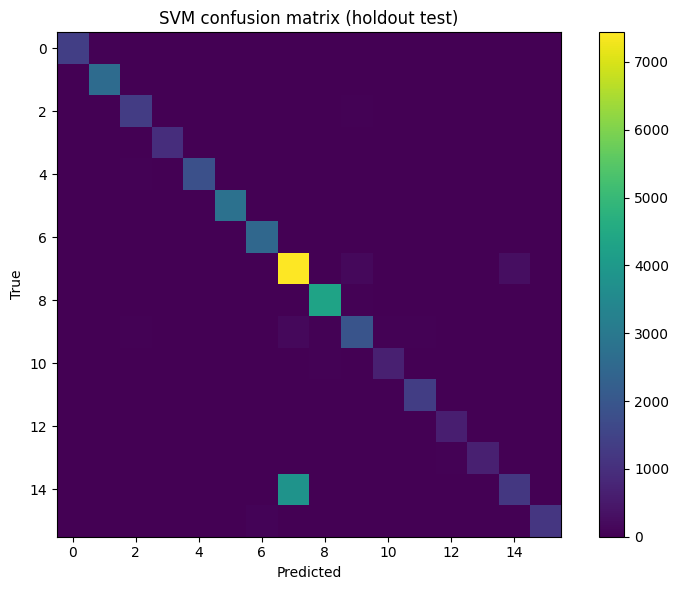

In [14]:
print(classification_report(
    y_svm_test_holdout,
    svm_test_pred,
    target_names=SALINAS_CLASS_NAMES,
    digits=4,
    zero_division=0
))

svm_classification_report_df = build_classification_report_df(
    y_svm_test_holdout,
    svm_test_pred,
    SALINAS_CLASS_NAMES
)
display(svm_classification_report_df)

svm_cm = confusion_matrix(y_svm_test_holdout, svm_test_pred)
plot_confusion(svm_cm, title="SVM confusion matrix (holdout test)")

svm_per_class_f1_df = build_per_class_f1_df(
    svm_test_metrics["per_class_f1"],
    model_name="svm"
)


# Часть II. 1D-CNN: только архитектуры из научных источников


## Разбиение данных для 1D-CNN

Для 1D-CNN используется **собственная** схема разбиения, независимая от схемы SVM.

## Как интерпретировать подбор CNN

Здесь **не задаётся произвольная сетка архитектур**.  
Вместо этого сравниваются только несколько **литературных архитектур**, а выбор лучшей модели делается по `validation macro-F1`.


In [15]:
cnn_indices = np.arange(len(y_all))

cnn_dev_idx, cnn_test_idx = train_test_split(
    cnn_indices,
    test_size=CNN_TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_all
)

cnn_train_idx, cnn_val_idx = train_test_split(
    cnn_dev_idx,
    test_size=CNN_VAL_SIZE_WITHIN_DEV,
    random_state=RANDOM_STATE,
    stratify=y_all[cnn_dev_idx]
)

X_cnn_dev = X_all[cnn_dev_idx]
y_cnn_dev = y_all[cnn_dev_idx]

X_cnn_test_holdout = X_all[cnn_test_idx]
y_cnn_test_holdout = y_all[cnn_test_idx]

X_cnn_train_raw = X_all[cnn_train_idx]
y_cnn_train = y_all[cnn_train_idx]

X_cnn_val_raw = X_all[cnn_val_idx]
y_cnn_val = y_all[cnn_val_idx]

print("CNN train :", X_cnn_train_raw.shape, y_cnn_train.shape)
print("CNN val   :", X_cnn_val_raw.shape, y_cnn_val.shape)
print("CNN test  :", X_cnn_test_holdout.shape, y_cnn_test_holdout.shape)


CNN train : (4329, 204) (4329,)
CNN val   : (1083, 204) (1083,)
CNN test  : (48717, 204) (48717,)


## Нормализация для 1D-CNN


In [16]:

cnn_mean, cnn_std = fit_standardizer(X_cnn_train_raw)

X_cnn_train_std = apply_standardizer(X_cnn_train_raw, cnn_mean, cnn_std)
X_cnn_val_std   = apply_standardizer(X_cnn_val_raw, cnn_mean, cnn_std)
X_cnn_dev_std   = apply_standardizer(X_cnn_dev, cnn_mean, cnn_std)
X_cnn_test_std  = apply_standardizer(X_cnn_test_holdout, cnn_mean, cnn_std)

X_cnn_train_t = torch.tensor(X_cnn_train_std, dtype=torch.float32).unsqueeze(1)
X_cnn_val_t   = torch.tensor(X_cnn_val_std, dtype=torch.float32).unsqueeze(1)
X_cnn_test_t  = torch.tensor(X_cnn_test_std, dtype=torch.float32).unsqueeze(1)

cnn_seq_len = X_cnn_train_std.shape[1]
cnn_seq_len


204

## Реализуемые архитектуры

### 1. Hu-style (2015)
Компактная 1D-CNN:
- `Conv1d(1 → 20)`
- `tanh`
- `max-pooling`
- `FC(100)`
- `softmax`

### 2. Hsieh–Kiang-style (2020)
Спектральная 1D-CNN:
- `Conv1d(1 → 20, kernel=2) + BN + ReLU + MaxPool(2)`
- `Conv1d(20 → 20, kernel=2) + BN + ReLU + MaxPool(2)`
- `Flatten + Linear(num_classes)`

### 3. Bera-style for Salinas (2022)
Архитектура для Salinas из обзорной сравнительной таблицы:
- `Conv1d(1 → 4, kernel=5) + Pool(2)`
- `Conv1d(4 → 8, kernel=5) + Pool(2)`
- `Conv1d(8 → 16, kernel=5) + Pool(2)`
- `Conv1d(16 → 32, kernel=5)`
- `Flatten + Linear(num_classes)`


In [17]:

class Hu2015CNN1D(nn.Module):
    def __init__(self, seq_len, num_classes, kernel_size=None, pool_out=35, hidden_dim=100):
        super().__init__()
        if kernel_size is None:
            kernel_size = max(3, math.ceil(seq_len / 9))

        self.features = nn.Sequential(
            nn.Conv1d(1, 20, kernel_size=kernel_size),
            nn.Tanh(),
            nn.AdaptiveMaxPool1d(pool_out)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(20 * pool_out, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


class HsiehKiang2020CNN1D(nn.Module):
    def __init__(self, seq_len, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 20, kernel_size=2),
            nn.BatchNorm1d(20),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(20, 20, kernel_size=2),
            nn.BatchNorm1d(20),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        with torch.no_grad():
            dummy = torch.zeros(1, 1, seq_len)
            flat_dim = self.features(dummy).view(1, -1).shape[1]

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


class Bera2022SalinasCNN1D(nn.Module):
    def __init__(self, seq_len, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 4, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(4, 8, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(8, 16, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(16, 32, kernel_size=5),
            nn.ReLU()
        )

        with torch.no_grad():
            dummy = torch.zeros(1, 1, seq_len)
            flat_dim = self.features(dummy).view(1, -1).shape[1]

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


## Active 1D-CNN configuration

The notebook contains implementations of several literature-inspired 1D-CNN families, but the saved final experiment uses the **Hu-style (2015)** configuration below.


In [18]:

CNN_LITERATURE_CONFIGS = [
    {
        "name": "hu2015_singleconv",
        "family": "hu2015",
        "source_note": "Hu et al. 2015 style",
        "batch_size": 100,
        "lr": 1e-3,
        "weight_decay": 0.0,
        "max_epochs": 200,
        "patience": CNN_COMMON_PATIENCE
    }
]

pd.DataFrame(CNN_LITERATURE_CONFIGS)


,name,family,source_note,batch_size,lr,weight_decay,max_epochs,patience
0,hu2015_singleconv,hu2015,Hu et al. 2015 style,100,0.001,0.0,200,20


## Фабрика моделей


In [19]:

def build_cnn_from_literature_config(config, seq_len, num_classes):
    family = config["family"]

    if family == "hu2015":
        return Hu2015CNN1D(seq_len=seq_len, num_classes=num_classes)
    elif family == "hsieh2020":
        return HsiehKiang2020CNN1D(seq_len=seq_len, num_classes=num_classes)
    elif family == "bera2022_sa":
        return Bera2022SalinasCNN1D(seq_len=seq_len, num_classes=num_classes)
    else:
        raise ValueError(f"Unknown CNN family: {family}")


## Обучение одной литературной конфигурации CNN


In [20]:

def train_cnn_candidate(
    config,
    X_train_t,
    y_train,
    X_val_t,
    y_val,
    seq_len,
    num_classes,
    device="cpu"
):
    set_seed(RANDOM_STATE)

    train_loader = DataLoader(
        TensorDataset(X_train_t, torch.tensor(y_train, dtype=torch.long)),
        batch_size=config["batch_size"],
        shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(X_val_t, torch.tensor(y_val, dtype=torch.long)),
        batch_size=config["batch_size"],
        shuffle=False
    )

    model = build_cnn_from_literature_config(config, seq_len=seq_len, num_classes=num_classes).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(1, config["max_epochs"] + 1):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == yb).sum().item()
            train_total += yb.size(0)

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)

                val_loss_sum += loss.item() * xb.size(0)
                preds = logits.argmax(dim=1)
                val_correct += (preds == yb).sum().item()
                val_total += yb.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= config["patience"]:
            break

    model.load_state_dict(best_state)

    val_pred = predict_torch_batches(
        model=model,
        X_t=X_val_t,
        batch_size=max(256, config["batch_size"]),
        device=device
    )

    val_metrics = compute_metrics(y_val, val_pred)

    return model, history, best_epoch, val_metrics, val_pred


## Подбор лучшей CNN среди литературных архитектур


In [21]:

cnn_search_rows = []
cnn_histories = {}
cnn_models = {}

for cfg in tqdm(CNN_LITERATURE_CONFIGS, desc="Literature CNN search"):
    model, history, best_epoch, val_metrics, val_pred = train_cnn_candidate(
        config=cfg,
        X_train_t=X_cnn_train_t,
        y_train=y_cnn_train,
        X_val_t=X_cnn_val_t,
        y_val=y_cnn_val,
        seq_len=cnn_seq_len,
        num_classes=num_classes,
        device=DEVICE
    )

    cnn_histories[cfg["name"]] = history
    cnn_models[cfg["name"]] = model

    cnn_search_rows.append({
        "name": cfg["name"],
        "family": cfg["family"],
        "source_note": cfg["source_note"],
        "batch_size": cfg["batch_size"],
        "lr": cfg["lr"],
        "weight_decay": cfg["weight_decay"],
        "max_epochs": cfg["max_epochs"],
        "best_epoch": best_epoch,
        "val_oa": val_metrics["oa"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_weighted_f1": val_metrics["weighted_f1"]
    })

cnn_search_df = pd.DataFrame(cnn_search_rows).sort_values(
    by="val_macro_f1", ascending=False
).reset_index(drop=True)

display(cnn_search_df)


Literature CNN search: 100%|██████████| 1/1 [00:18<00:00, 18.39s/it]


,name,family,source_note,batch_size,lr,weight_decay,max_epochs,best_epoch,val_oa,val_macro_f1,val_weighted_f1
0,hu2015_singleconv,hu2015,Hu et al. 2015 style,100,0.001,0.0,200,141,0.951062,0.976806,0.950671


## Лучшая литературная конфигурация CNN


In [22]:

best_cnn_cfg = cnn_search_df.iloc[0].to_dict()
best_cnn_cfg


{'name': 'hu2015_singleconv',
 'family': 'hu2015',
 'source_note': 'Hu et al. 2015 style',
 'batch_size': 100,
 'lr': 0.001,
 'weight_decay': 0.0,
 'max_epochs': 200,
 'best_epoch': 141,
 'val_oa': 0.951061865189289,
 'val_macro_f1': 0.9768059603579831,
 'val_weighted_f1': 0.9506710797501728}

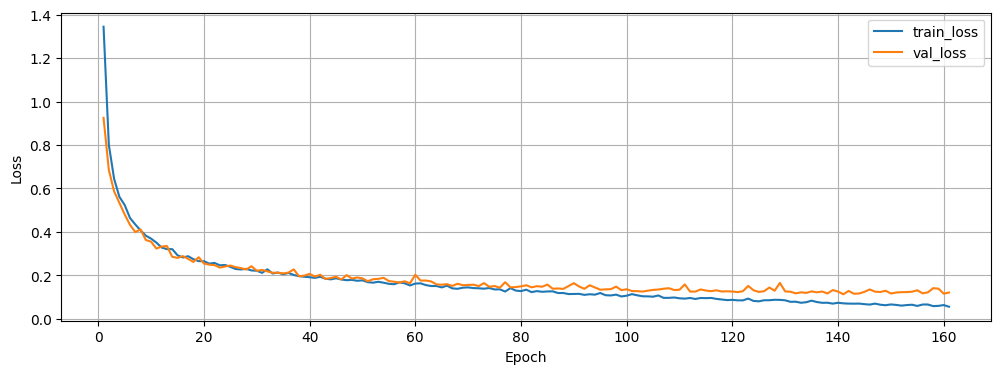

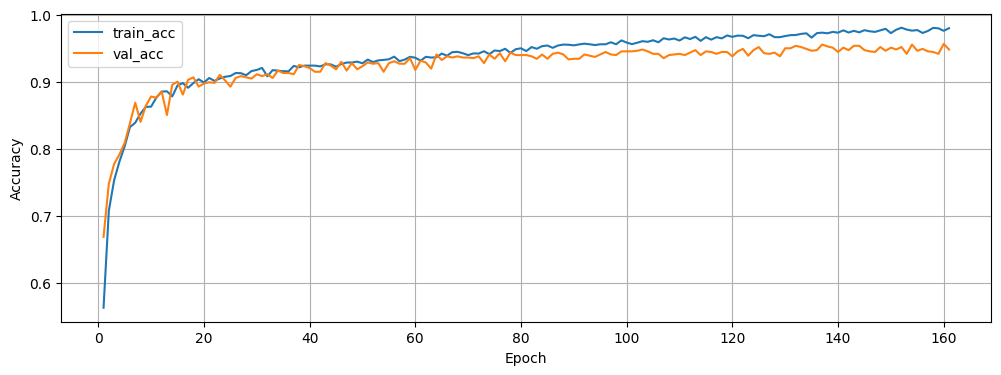

In [23]:

best_cnn_name = best_cnn_cfg["name"]
best_cnn_history = pd.DataFrame(cnn_histories[best_cnn_name])

plt.figure(figsize=(12, 4))
plt.plot(best_cnn_history["epoch"], best_cnn_history["train_loss"], label="train_loss")
plt.plot(best_cnn_history["epoch"], best_cnn_history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(best_cnn_history["epoch"], best_cnn_history["train_acc"], label="train_acc")
plt.plot(best_cnn_history["epoch"], best_cnn_history["val_acc"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## Переобучение лучшей CNN на всей development-части


In [24]:

def fit_cnn_for_fixed_epochs(
    config,
    X_train_full,
    y_train_full,
    seq_len,
    num_classes,
    epochs,
    device="cpu"
):
    set_seed(RANDOM_STATE)

    X_train_full_t = torch.tensor(X_train_full, dtype=torch.float32).unsqueeze(1)
    y_train_full_t = torch.tensor(y_train_full, dtype=torch.long)

    train_loader = DataLoader(
        TensorDataset(X_train_full_t, y_train_full_t),
        batch_size=int(config["batch_size"]),
        shuffle=True
    )

    model = build_cnn_from_literature_config(config, seq_len=seq_len, num_classes=num_classes).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=float(config["lr"]),
        weight_decay=float(config["weight_decay"])
    )

    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": []
    }

    for epoch in range(1, int(epochs) + 1):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == yb).sum().item()
            train_total += yb.size(0)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss_sum / train_total)
        history["train_acc"].append(train_correct / train_total)

    return model, history


In [25]:

selected_cnn_cfg = next(cfg for cfg in CNN_LITERATURE_CONFIGS if cfg["name"] == best_cnn_name)
selected_best_epoch = int(best_cnn_cfg["best_epoch"])

if CNN_RETRAIN_ON_FULL_DEV:
    cnn_final_mean, cnn_final_std = fit_standardizer(X_cnn_dev)
    X_cnn_dev_final_std  = apply_standardizer(X_cnn_dev, cnn_final_mean, cnn_final_std)
    X_cnn_test_final_std = apply_standardizer(X_cnn_test_holdout, cnn_final_mean, cnn_final_std)

    cnn_model_final, cnn_final_history = fit_cnn_for_fixed_epochs(
        config=selected_cnn_cfg,
        X_train_full=X_cnn_dev_final_std,
        y_train_full=y_cnn_dev,
        seq_len=cnn_seq_len,
        num_classes=num_classes,
        epochs=selected_best_epoch,
        device=DEVICE
    )
else:
    cnn_final_mean, cnn_final_std = cnn_mean, cnn_std
    X_cnn_test_final_std = apply_standardizer(X_cnn_test_holdout, cnn_final_mean, cnn_final_std)
    cnn_model_final = cnn_models[best_cnn_name]


# Часть III. Финальное тестирование


## Тестирование SVM


In [26]:

svm_test_summary_df = pd.DataFrame([{
    "model": "SVM",
    "test_size": 0.7,
    "test_OA": svm_test_metrics["oa"],
    "test_macro_F1": svm_test_metrics["macro_f1"],
    "test_weighted_F1": svm_test_metrics["weighted_f1"]
}])

display(svm_test_summary_df)


,model,test_size,test_OA,test_macro_F1,test_weighted_F1
0,SVM,0.7,0.862817,0.908073,0.843448


## Тестирование лучшей литературной 1D-CNN


In [27]:

X_cnn_test_final_t = torch.tensor(X_cnn_test_final_std, dtype=torch.float32).unsqueeze(1)

cnn_test_pred = predict_torch_batches(
    cnn_model_final,
    X_cnn_test_final_t,
    batch_size=2048,
    device=DEVICE
)

cnn_test_metrics = compute_metrics(y_cnn_test_holdout, cnn_test_pred)

print("CNN holdout test OA         :", round(cnn_test_metrics["oa"], 6))
print("CNN holdout test macro-F1   :", round(cnn_test_metrics["macro_f1"], 6))
print("CNN holdout test weighted-F1:", round(cnn_test_metrics["weighted_f1"], 6))


CNN holdout test OA         : 0.947493
CNN holdout test macro-F1   : 0.971709
CNN holdout test weighted-F1: 0.946607


                           precision    recall  f1-score   support

    Brocoli_green_weeds_1     0.9994    1.0000    0.9997      1808
    Brocoli_green_weeds_2     0.9991    1.0000    0.9996      3354
                   Fallow     0.9949    0.9927    0.9938      1779
        Fallow_rough_plow     0.9888    0.9880    0.9884      1255
            Fallow_smooth     0.9815    0.9917    0.9866      2410
                  Stubble     0.9994    0.9986    0.9990      3563
                   Celery     1.0000    0.9960    0.9980      3221
         Grapes_untrained     0.8499    0.9361    0.8909     10144
     Soil_vinyard_develop     0.9925    0.9993    0.9959      5583
Corn_senesced_green_weeds     0.9826    0.9746    0.9786      2950
      Lettuce_romaine_4wk     0.9978    0.9625    0.9799       961
      Lettuce_romaine_5wk     0.9725    0.9994    0.9858      1734
      Lettuce_romaine_6wk     0.9636    0.9952    0.9791       825
      Lettuce_romaine_7wk     0.9859    0.9450    0.9650     

,label,precision,recall,f1-score,support
0,Brocoli_green_weeds_1,0.999447,1.000000,0.999724,1808.000000
1,Brocoli_green_weeds_2,0.999106,1.000000,0.999553,3354.000000
2,Fallow,0.994930,0.992693,0.993810,1779.000000
3,Fallow_rough_plow,0.988836,0.988048,0.988442,1255.000000
4,Fallow_smooth,0.981520,0.991701,0.986584,2410.000000
5,Stubble,0.999438,0.998597,0.999017,3563.000000
6,Celery,1.000000,0.995964,0.997978,3221.000000
7,Grapes_untrained,0.849906,0.936120,0.890932,10144.000000
8,Soil_vinyard_develop,0.992528,0.999284,0.995894,5583.000000
9,Corn_senesced_green_weeds,0.982570,0.974576,0.978557,2950.000000


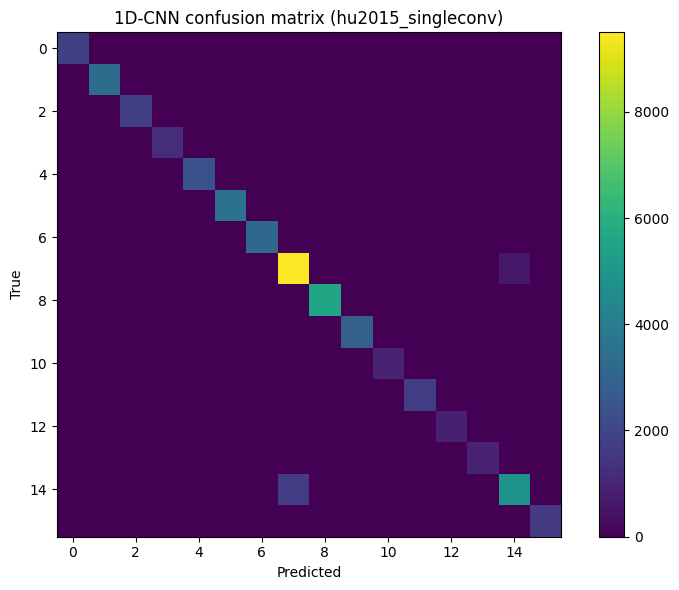

In [28]:
print(classification_report(
    y_cnn_test_holdout,
    cnn_test_pred,
    target_names=SALINAS_CLASS_NAMES,
    digits=4,
    zero_division=0
))

cnn_classification_report_df = build_classification_report_df(
    y_cnn_test_holdout,
    cnn_test_pred,
    SALINAS_CLASS_NAMES
)
display(cnn_classification_report_df)

cnn_test_cm = confusion_matrix(y_cnn_test_holdout, cnn_test_pred)
plot_confusion(cnn_test_cm, title=f"1D-CNN confusion matrix ({best_cnn_name})")

cnn_per_class_f1_df = build_per_class_f1_df(
    cnn_test_metrics["per_class_f1"],
    model_name="cnn"
)


In [44]:
X_svm_test_final_pca = svm_pca_final.transform(X_svm_test_final_std)

svm_test_pred = svm_model_final.predict(X_svm_test_final_pca)

svm_test_metrics = compute_metrics(y_svm_test_holdout, svm_test_pred)

print("SVM holdout test OA         :", round(svm_test_metrics["oa"], 6))
print("SVM holdout test macro-F1   :", round(svm_test_metrics["macro_f1"], 6))
print("SVM holdout test weighted-F1:", round(svm_test_metrics["weighted_f1"], 6))

NameError: name 'svm_pca_final' is not defined

## Карты классификации только по обучающей выборке

Ниже показаны только те пиксели, которые входили в обучающую часть каждого эксперимента. Остальная сцена обнулена, поэтому на карте остаются только соответствующие фрагменты обучающей выборки.


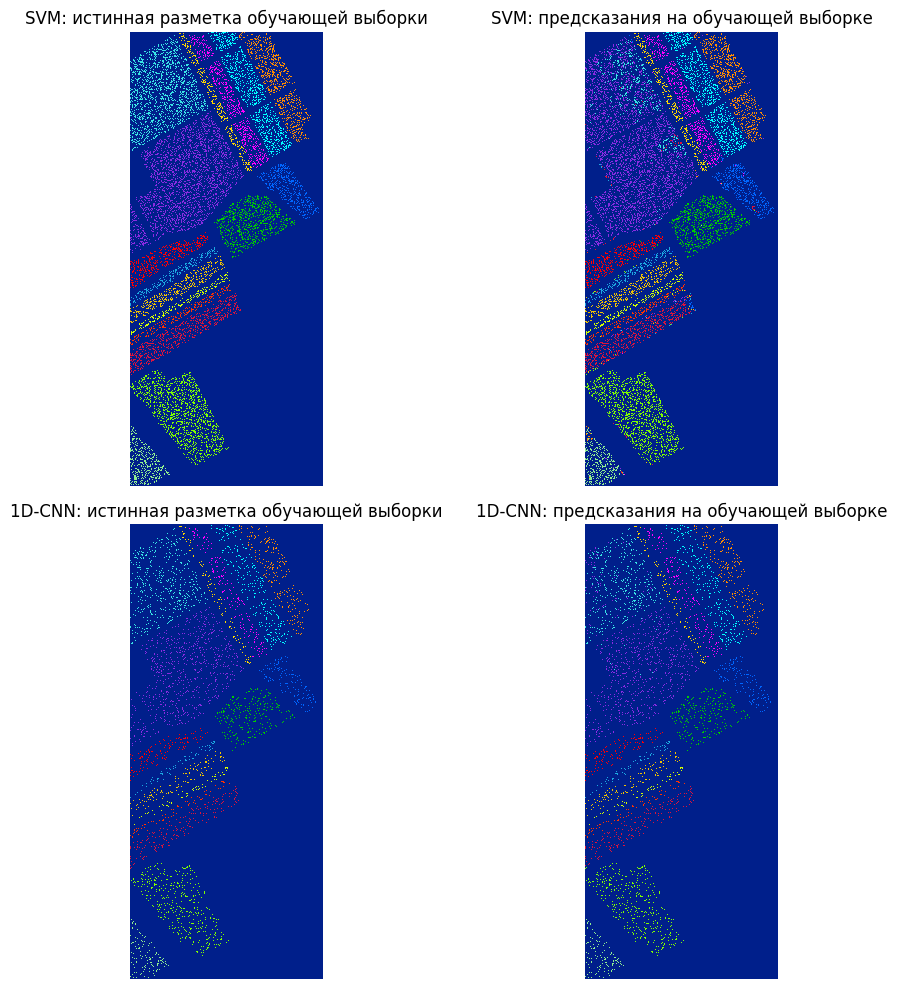

In [29]:
svm_train_final_std = apply_standardizer(X_all[svm_train_idx], svm_final_mean, svm_final_std)
svm_train_final_pca = svm_final_pca.transform(svm_train_final_std)
svm_train_pred = best_svm_model.predict(svm_train_final_pca)

svm_train_gt_map = make_masked_map_from_indices(
    svm_train_idx,
    y_all[svm_train_idx],
    gt.shape,
    labeled_coords
)
svm_train_pred_map = make_masked_map_from_indices(
    svm_train_idx,
    svm_train_pred,
    gt.shape,
    labeled_coords
)

cnn_train_final_std = apply_standardizer(X_all[cnn_train_idx], cnn_final_mean, cnn_final_std)
X_cnn_train_final_t = torch.tensor(cnn_train_final_std, dtype=torch.float32).unsqueeze(1)
cnn_train_pred = predict_torch_batches(
    cnn_model_final,
    X_cnn_train_final_t,
    batch_size=2048,
    device=DEVICE
)

cnn_train_gt_map = make_masked_map_from_indices(
    cnn_train_idx,
    y_all[cnn_train_idx],
    gt.shape,
    labeled_coords
)
cnn_train_pred_map = make_masked_map_from_indices(
    cnn_train_idx,
    cnn_train_pred,
    gt.shape,
    labeled_coords
)

fig, axs = plt.subplots(2, 2, figsize=(12, 10))

plot_map(axs[0, 0], svm_train_gt_map, "SVM: истинная разметка обучающей выборки")
plot_map(axs[0, 1], svm_train_pred_map, "SVM: предсказания на обучающей выборке")
plot_map(axs[1, 0], cnn_train_gt_map, "1D-CNN: истинная разметка обучающей выборки")
plot_map(axs[1, 1], cnn_train_pred_map, f"1D-CNN: предсказания на обучающей выборке")

plt.tight_layout()
plt.show()


## Итоговые таблицы


In [30]:

summary_df = pd.DataFrame([
    {
        "model": "SVM",
        "test_size": 0.7,
        "test_OA": svm_test_metrics["oa"],
        "test_macro_F1": svm_test_metrics["macro_f1"],
        "test_weighted_F1": svm_test_metrics["weighted_f1"]
    },
    {
        "model": f"1D-CNN",
        "test_size": CNN_TEST_SIZE,
        "test_OA": cnn_test_metrics["oa"],
        "test_macro_F1": cnn_test_metrics["macro_f1"],
        "test_weighted_F1": cnn_test_metrics["weighted_f1"]
    }
])

display(summary_df)


,model,test_size,test_OA,test_macro_F1,test_weighted_F1
0,SVM,0.7,0.862817,0.908073,0.843448
1,1D-CNN,0.9,0.947493,0.971709,0.946607


In [31]:

per_class_compare_df = svm_per_class_f1_df.merge(
    cnn_per_class_f1_df,
    on=["class_id", "class_name"],
    how="outer"
)

display(per_class_compare_df)


,class_id,class_name,svm_f1,cnn_f1
0,0,Brocoli_green_weeds_1,0.988489,0.999724
1,1,Brocoli_green_weeds_2,0.992567,0.999553
2,2,Fallow,0.944346,0.993810
3,3,Fallow_rough_plow,0.980612,0.988442
4,4,Fallow_smooth,0.970572,0.986584
5,5,Stubble,0.998735,0.999017
6,6,Celery,0.983445,0.997978
7,7,Grapes_untrained,0.768325,0.890932
8,8,Soil_vinyard_develop,0.987034,0.995894
9,9,Corn_senesced_green_weeds,0.859048,0.978557


## Сохранение артефактов


In [32]:

joblib.dump(best_svm_model, ARTIFACT_DIR / "best_svm_model.joblib")
joblib.dump(svm_final_pca, ARTIFACT_DIR / "best_svm_pca.joblib")
np.savez(
    ARTIFACT_DIR / "best_svm_standardizer.npz",
    mean=svm_final_mean,
    std=svm_final_std
)

torch.save(cnn_model_final.state_dict(), ARTIFACT_DIR / "best_literature_1dcnn_state_dict.pt")
np.savez(
    ARTIFACT_DIR / "best_literature_1dcnn_standardizer.npz",
    mean=cnn_final_mean,
    std=cnn_final_std
)

svm_results_df.to_csv(ARTIFACT_DIR / "svm_validation_search.csv", index=False)
cnn_search_df.to_csv(ARTIFACT_DIR / "cnn_literature_validation_search.csv", index=False)
summary_df.to_csv(ARTIFACT_DIR / "summary_test_metrics.csv", index=False)
per_class_compare_df.to_csv(ARTIFACT_DIR / "per_class_compare_test.csv", index=False)

print("Artifacts saved to:", ARTIFACT_DIR.resolve())


Artifacts saved to: C:\Users\denis\Desktop\111\artifacts_salinas_literature_1dcnn


## Краткая интерпретация схемы

### Для SVM
1. Разделение на `development` и `holdout test`.
2. Внутри `development`: `train` и `validation`.
3. Подбор гиперпараметров по `validation`.
4. Переобучение на всей `development`-части.
5. Однократное тестирование на `holdout test`.

### Для 1D-CNN
1. Отдельное разделение на `development` и `holdout test`.
2. Внутри `development`: `train` и `validation`.
3. Сравнение **только литературных архитектур**.
4. Выбор лучшей CNN по `validation macro-F1`.
5. Переобучение выбранной архитектуры на всей `development`-части.
6. Однократное тестирование на `holdout test`.


In [33]:
best_cnn_cfg = cnn_search_df.iloc[0].to_dict()

best_cnn_cfg_df = pd.DataFrame(
    list(best_cnn_cfg.items()),
    columns=["parameter", "value"]
)

display(best_cnn_cfg_df)

,parameter,value
0,name,hu2015_singleconv
1,family,hu2015
2,source_note,Hu et al. 2015 style
3,batch_size,100
4,lr,0.001
5,weight_decay,0.0
6,max_epochs,200
7,best_epoch,141
8,val_oa,0.951062
9,val_macro_f1,0.976806


## Дополнительно: итоговые карты классификации на Salinas

Ниже строятся итоговые карты классификации для всей размеченной части сцены Salinas.  
Используются финальные модели, уже полученные в ноутбуке: `best_svm_model` и `cnn_model_final` (Hu-style 1D-CNN).


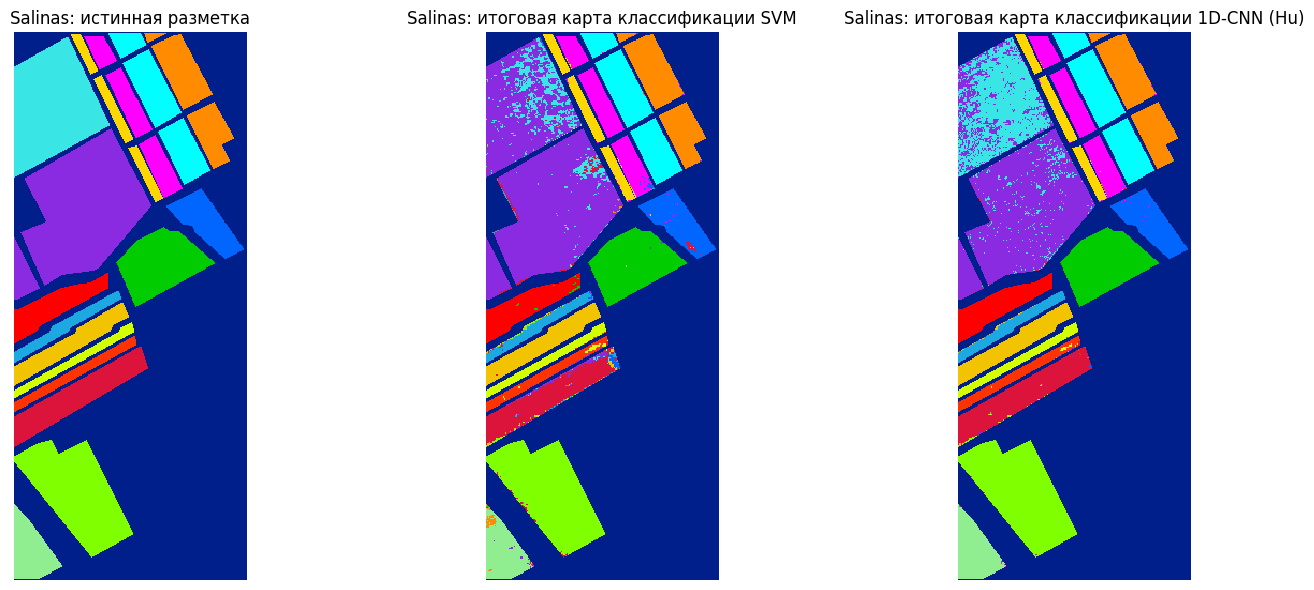

In [34]:

# Итоговые карты классификации на всей размеченной части Salinas

all_labeled_idx = np.arange(len(y_all))

# SVM: предсказания по всей размеченной части сцены
X_svm_all_std = apply_standardizer(X_all, svm_final_mean, svm_final_std)
X_svm_all_pca = svm_final_pca.transform(X_svm_all_std)
svm_all_pred = best_svm_model.predict(X_svm_all_pca)

salinas_gt_map = gt.copy().astype(np.int64)
salinas_svm_pred_map = make_masked_map_from_indices(
    all_labeled_idx,
    svm_all_pred,
    gt.shape,
    labeled_coords
)

# 1D-CNN (Hu-style): предсказания по всей размеченной части сцены
X_cnn_all_std = apply_standardizer(X_all, cnn_final_mean, cnn_final_std)
X_cnn_all_t = torch.tensor(X_cnn_all_std, dtype=torch.float32).unsqueeze(1)
cnn_all_pred = predict_torch_batches(
    cnn_model_final,
    X_cnn_all_t,
    batch_size=2048,
    device=DEVICE
)

salinas_cnn_pred_map = make_masked_map_from_indices(
    all_labeled_idx,
    cnn_all_pred,
    gt.shape,
    labeled_coords
)

fig, axs = plt.subplots(1, 3, figsize=(16, 6))
plot_map(axs[0], salinas_gt_map, "Salinas: истинная разметка")
plot_map(axs[1], salinas_svm_pred_map, "Salinas: итоговая карта классификации SVM")
plot_map(axs[2], salinas_cnn_pred_map, "Salinas: итоговая карта классификации 1D-CNN (Hu)")
plt.tight_layout()
plt.show()


## Дополнительно: обучение и тестирование моделей на Pavia Centre

In [35]:
# Пути к данным Pavia Centre.
# При необходимости замените имена файлов на используемые в вашей папке.
PAVIA_CANDIDATE_DATA_PATHS = [
    Path("data/Pavia.mat"),
    Path("data/Pavia_center.mat"),
    Path("data/PaviaCentre.mat"),
    Path("data/Pavia_centre.mat"),
    Path("data/Pavia Center.mat"),
]

PAVIA_CANDIDATE_GT_PATHS = [
    Path("data/Pavia_gt.mat"),
    Path("data/Pavia_center_gt.mat"),
    Path("data/PaviaCentre_gt.mat"),
    Path("data/Pavia_centre_gt.mat"),
    Path("data/Pavia Center_gt.mat"),
]

def resolve_existing_path(candidates):
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        "Не найден ни один из файлов: " + ", ".join(str(p) for p in candidates)
    )

pavia_data_path = resolve_existing_path(PAVIA_CANDIDATE_DATA_PATHS)
pavia_gt_path = resolve_existing_path(PAVIA_CANDIDATE_GT_PATHS)

pavia_cube = _load_mat_array(
    pavia_data_path,
    ["pavia", "Pavia", "pavia_center", "Pavia_center", "cube"]
).astype(np.float32)

pavia_gt = _load_mat_array(
    pavia_gt_path,
    ["pavia_gt", "Pavia_gt", "pavia_center_gt", "Pavia_center_gt", "gt"]
).astype(np.int64)

if pavia_gt.ndim == 3 and pavia_gt.shape[-1] == 1:
    pavia_gt = pavia_gt[..., 0]

pavia_mask = pavia_gt > 0
pavia_labeled_coords = np.argwhere(pavia_mask)
X_pavia_all = pavia_cube[pavia_mask].astype(np.float32)
y_pavia_raw = pavia_gt[pavia_mask].astype(np.int64)

pavia_label_values = np.sort(np.unique(y_pavia_raw))
pavia_label_to_index = {label: idx for idx, label in enumerate(pavia_label_values)}
pavia_index_to_label = {idx: label for label, idx in pavia_label_to_index.items()}

y_pavia_all = np.array([pavia_label_to_index[v] for v in y_pavia_raw], dtype=np.int64)
pavia_num_classes = len(pavia_label_values)
PAVIA_CLASS_NAMES = [f"Pavia_class_{int(v)}" for v in pavia_label_values]

def compute_metrics_for_num_classes(y_true, y_pred, n_classes):
    return {
        "oa": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "per_class_f1": f1_score(
            y_true,
            y_pred,
            average=None,
            labels=np.arange(n_classes),
            zero_division=0
        )
    }

print("Pavia Centre loaded:")
print("cube shape:", pavia_cube.shape)
print("gt shape  :", pavia_gt.shape)
print("labeled pixels:", len(y_pavia_all))
print("Pavia class labels:", pavia_label_values)

Pavia Centre loaded:
cube shape: (1096, 715, 102)
gt shape  : (1096, 715)
labeled pixels: 148152
Pavia class labels: [1 2 3 4 5 6 7 8 9]


In [36]:
# -------------------------
# SVM на Pavia Centre
# -------------------------
pavia_svm_train_idx, pavia_svm_test_idx = train_test_split(
    np.arange(len(y_pavia_all)),
    test_size=SVM_TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_pavia_all
)

X_pavia_svm_train = X_pavia_all[pavia_svm_train_idx]
y_pavia_svm_train = y_pavia_all[pavia_svm_train_idx]
X_pavia_svm_test = X_pavia_all[pavia_svm_test_idx]
y_pavia_svm_test = y_pavia_all[pavia_svm_test_idx]

pavia_svm_mean, pavia_svm_std = fit_standardizer(X_pavia_svm_train)
X_pavia_svm_train_std = apply_standardizer(X_pavia_svm_train, pavia_svm_mean, pavia_svm_std)
X_pavia_svm_test_std = apply_standardizer(X_pavia_svm_test, pavia_svm_mean, pavia_svm_std)

pavia_svm_pca = PCA(
    n_components=int(30),
    random_state=RANDOM_STATE
)

X_pavia_svm_train_pca = pavia_svm_pca.fit_transform(X_pavia_svm_train_std)
X_pavia_svm_test_pca = pavia_svm_pca.transform(X_pavia_svm_test_std)

pavia_svm_model = SVC(
    kernel="rbf",
    gamma=0.0005,
    class_weight=None if pd.isna(best_svm_cfg["class_weight"]) else best_svm_cfg["class_weight"]
)
pavia_svm_model.fit(X_pavia_svm_train_pca, y_pavia_svm_train)

pavia_svm_test_pred = pavia_svm_model.predict(X_pavia_svm_test_pca)
pavia_svm_test_metrics = compute_metrics_for_num_classes(
    y_pavia_svm_test,
    pavia_svm_test_pred,
    pavia_num_classes
)

print("Pavia SVM test OA         :", round(pavia_svm_test_metrics["oa"], 6))
print("Pavia SVM test macro-F1   :", round(pavia_svm_test_metrics["macro_f1"], 6))
print("Pavia SVM test weighted-F1:", round(pavia_svm_test_metrics["weighted_f1"], 6))

print(classification_report(
    y_pavia_svm_test,
    pavia_svm_test_pred,
    labels=np.arange(pavia_num_classes),
    target_names=PAVIA_CLASS_NAMES,
    digits=4,
    zero_division=0
))

# -------------------------
# 1D-CNN (Hu) на Pavia Centre
# -------------------------
pavia_cnn_train_idx, pavia_cnn_test_idx = train_test_split(
    np.arange(len(y_pavia_all)),
    test_size=CNN_TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_pavia_all
)

X_pavia_cnn_train = X_pavia_all[pavia_cnn_train_idx]
y_pavia_cnn_train = y_pavia_all[pavia_cnn_train_idx]
X_pavia_cnn_test = X_pavia_all[pavia_cnn_test_idx]
y_pavia_cnn_test = y_pavia_all[pavia_cnn_test_idx]

pavia_cnn_mean, pavia_cnn_std = fit_standardizer(X_pavia_cnn_train)
X_pavia_cnn_train_std = apply_standardizer(X_pavia_cnn_train, pavia_cnn_mean, pavia_cnn_std)
X_pavia_cnn_test_std = apply_standardizer(X_pavia_cnn_test, pavia_cnn_mean, pavia_cnn_std)

pavia_cnn_seq_len = X_pavia_cnn_train_std.shape[1]

pavia_cnn_model, pavia_cnn_history = fit_cnn_for_fixed_epochs(
    config=selected_cnn_cfg,
    X_train_full=X_pavia_cnn_train_std,
    y_train_full=y_pavia_cnn_train,
    seq_len=pavia_cnn_seq_len,
    num_classes=pavia_num_classes,
    epochs=selected_best_epoch,
    device=DEVICE
)

X_pavia_cnn_test_t = torch.tensor(X_pavia_cnn_test_std, dtype=torch.float32).unsqueeze(1)
pavia_cnn_test_pred = predict_torch_batches(
    pavia_cnn_model,
    X_pavia_cnn_test_t,
    batch_size=2048,
    device=DEVICE
)
pavia_cnn_test_metrics = compute_metrics_for_num_classes(
    y_pavia_cnn_test,
    pavia_cnn_test_pred,
    pavia_num_classes
)

print("Pavia 1D-CNN test OA         :", round(pavia_cnn_test_metrics["oa"], 6))
print("Pavia 1D-CNN test macro-F1   :", round(pavia_cnn_test_metrics["macro_f1"], 6))
print("Pavia 1D-CNN test weighted-F1:", round(pavia_cnn_test_metrics["weighted_f1"], 6))

print(classification_report(
    y_pavia_cnn_test,
    pavia_cnn_test_pred,
    labels=np.arange(pavia_num_classes),
    target_names=PAVIA_CLASS_NAMES,
    digits=4,
    zero_division=0
))

Pavia SVM test OA         : 0.969028
Pavia SVM test macro-F1   : 0.896738
Pavia SVM test weighted-F1: 0.968675
               precision    recall  f1-score   support

Pavia_class_1     0.9996    0.9990    0.9993     46180
Pavia_class_2     0.9230    0.9199    0.9215      5319
Pavia_class_3     0.7977    0.8040    0.8008      2163
Pavia_class_4     0.6891    0.5993    0.6410      1879
Pavia_class_5     0.8972    0.9390    0.9176      4609
Pavia_class_6     0.8864    0.9614    0.9223      6474
Pavia_class_7     0.9113    0.8436    0.8761      5101
Pavia_class_8     0.9959    0.9924    0.9941     29978
Pavia_class_9     0.9990    0.9965    0.9978      2004

     accuracy                         0.9690    103707
    macro avg     0.8999    0.8950    0.8967    103707
 weighted avg     0.9688    0.9690    0.9687    103707

Pavia 1D-CNN test OA         : 0.991698
Pavia 1D-CNN test macro-F1   : 0.973497
Pavia 1D-CNN test weighted-F1: 0.991717
               precision    recall  f1-score   supp

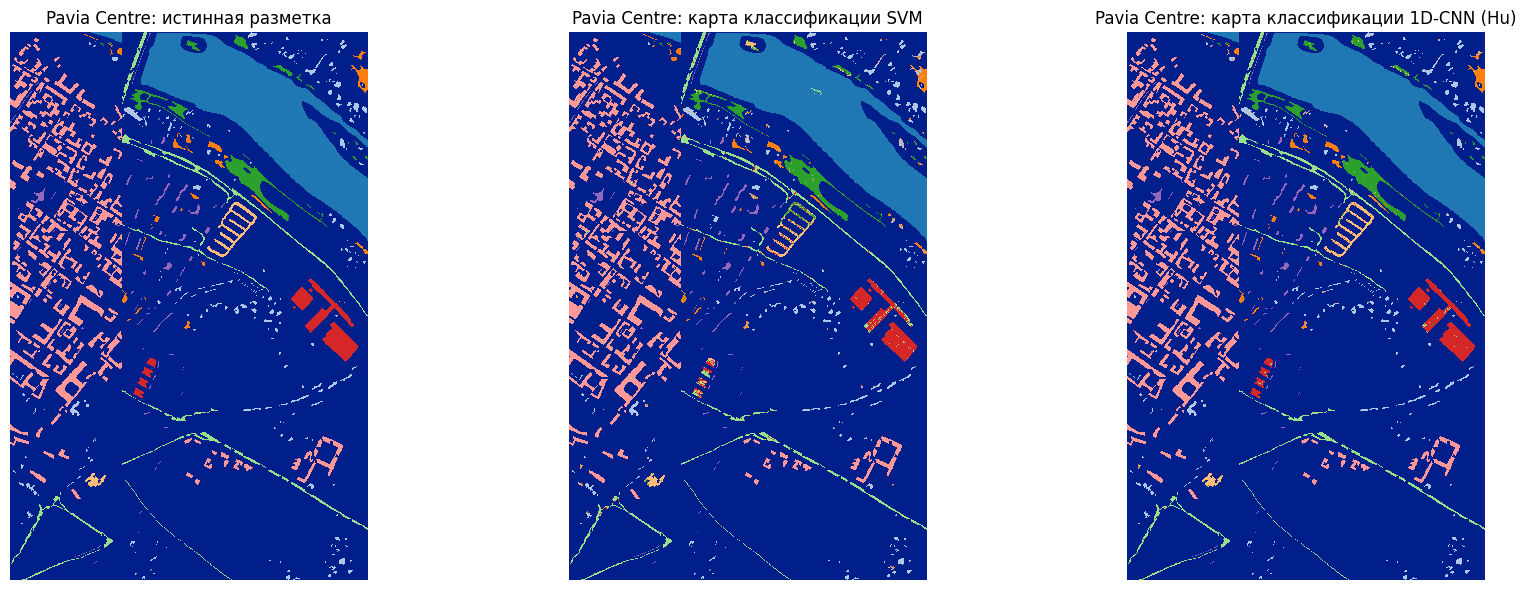

,dataset,model,test_size,test_OA,test_macro_F1,test_weighted_F1
0,Pavia Centre,SVM,0.7,0.969028,0.896738,0.968675
1,Pavia Centre,1D-CNN (Hu),0.9,0.991698,0.973497,0.991717


In [37]:
# Карты классификации на всей размеченной части Pavia Centre

X_pavia_svm_all_std = apply_standardizer(X_pavia_all, pavia_svm_mean, pavia_svm_std)
X_pavia_svm_all_pca = pavia_svm_pca.transform(X_pavia_svm_all_std)
pavia_svm_all_pred = pavia_svm_model.predict(X_pavia_svm_all_pca)

X_pavia_cnn_all_std = apply_standardizer(X_pavia_all, pavia_cnn_mean, pavia_cnn_std)
X_pavia_cnn_all_t = torch.tensor(X_pavia_cnn_all_std, dtype=torch.float32).unsqueeze(1)
pavia_cnn_all_pred = predict_torch_batches(
    pavia_cnn_model,
    X_pavia_cnn_all_t,
    batch_size=2048,
    device=DEVICE
)

pavia_gt_map = np.zeros_like(pavia_gt, dtype=np.int64)
pavia_gt_map[pavia_labeled_coords[:, 0], pavia_labeled_coords[:, 1]] = y_pavia_raw

pavia_svm_pred_map = np.zeros_like(pavia_gt, dtype=np.int64)
pavia_svm_pred_map[pavia_labeled_coords[:, 0], pavia_labeled_coords[:, 1]] = np.array(
    [pavia_index_to_label[idx] for idx in pavia_svm_all_pred],
    dtype=np.int64
)

pavia_cnn_pred_map = np.zeros_like(pavia_gt, dtype=np.int64)
pavia_cnn_pred_map[pavia_labeled_coords[:, 0], pavia_labeled_coords[:, 1]] = np.array(
    [pavia_index_to_label[idx] for idx in pavia_cnn_all_pred],
    dtype=np.int64
)

def get_dynamic_cmap(n_classes_plus_bg):
    base = ["#001f8b"]
    extra = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors) + list(plt.cm.tab20c.colors)
    needed = max(0, n_classes_plus_bg - 1)
    colors = base + [extra[i % len(extra)] for i in range(needed)]
    return ListedColormap(colors[:n_classes_plus_bg])

pavia_cmap = get_dynamic_cmap(int(pavia_gt.max()) + 1)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))

axs[0].imshow(pavia_gt_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[0].set_title("Pavia Centre: истинная разметка")
axs[0].axis("off")

axs[1].imshow(pavia_svm_pred_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[1].set_title("Pavia Centre: карта классификации SVM")
axs[1].axis("off")

axs[2].imshow(pavia_cnn_pred_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[2].set_title("Pavia Centre: карта классификации 1D-CNN (Hu)")
axs[2].axis("off")

plt.tight_layout()
plt.show()

pavia_summary_df = pd.DataFrame([
    {
        "dataset": "Pavia Centre",
        "model": "SVM",
        "test_size": SVM_TEST_SIZE,
        "test_OA": pavia_svm_test_metrics["oa"],
        "test_macro_F1": pavia_svm_test_metrics["macro_f1"],
        "test_weighted_F1": pavia_svm_test_metrics["weighted_f1"]
    },
    {
        "dataset": "Pavia Centre",
        "model": "1D-CNN (Hu)",
        "test_size": CNN_TEST_SIZE,
        "test_OA": pavia_cnn_test_metrics["oa"],
        "test_macro_F1": pavia_cnn_test_metrics["macro_f1"],
        "test_weighted_F1": pavia_cnn_test_metrics["weighted_f1"]
    }
])

display(pavia_summary_df)

# Часть IV. Дополнительно: 3-2D BERT из первого ноутбука

В этом блоке добавляется модель **3-2D BERT / D2BERT** из `combined_indian_pines_models_v2.ipynb`.

Переносимая конфигурация:
- PCA до 30 спектральных компонент;
- локальное окно `3×3`;
- вход Transformer: последовательность из 9 элементов, каждый элемент содержит 30 PCA-признаков;
- `d_model = 64`;
- `num_layers = 2`;
- `num_heads = 1`;
- `batch_size = 64`;
- `lr = 0.007`;
- максимум 30 эпох;
- early stopping с `patience = 10`.

Для сопоставимости со вторым ноутбуком модель обучается и оценивается отдельно на **Salinas** и **Pavia Centre** с использованием train/val/test-схемы и сбором OA, macro-F1, weighted-F1 и F1 по классам.


In [38]:

# ------------------------------------------------------------
# 3-2D BERT / D2BERT: конфигурация и общие функции
# ------------------------------------------------------------

D2BERT_CONFIG = {
    "pca_bands": 30,
    "patch_size": 3,
    "batch_size": 64,
    "lr": 0.007,
    "max_epochs": 30,
    "patience": 10,
    "num_layers": 2,
    "num_heads": 1,
    "d_model": 64,
    "retrain_on_full_dev": True,
    "inference_batch_size": 1024,
}

class D2BERT(nn.Module):
    """
    Конфигурация перенесена из combined_indian_pines_models_v2.ipynb.

    Вход:
        x: (batch, seq_len, feature_dim),
        где seq_len = patch_size * patch_size,
        feature_dim = число PCA-компонент.
    """
    def __init__(self, seq_len, feature_dim, d_model, num_classes, num_layers, num_heads):
        super().__init__()
        self.embedding = nn.Linear(feature_dim, d_model)
        self.pos_embed = nn.Parameter(torch.zeros(1, seq_len, d_model))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x):
        x = self.embedding(x) + self.pos_embed
        x = x.permute(1, 0, 2)  # (seq_len, batch, d_model)
        x = self.transformer(x)
        x = x.mean(dim=0)
        return self.classifier(x)


def compute_metrics_n_classes(y_true, y_pred, n_classes):
    return {
        "oa": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "per_class_f1": f1_score(
            y_true,
            y_pred,
            average=None,
            labels=np.arange(n_classes),
            zero_division=0
        )
    }


def fit_band_standardizer_from_coords(cube_arr, coords):
    spectra = cube_arr[coords[:, 0], coords[:, 1], :]
    mean = spectra.mean(axis=0, keepdims=True)
    std = spectra.std(axis=0, keepdims=True) + 1e-8
    return mean.astype(np.float32), std.astype(np.float32)


def normalize_cube_by_bands(cube_arr, mean, std):
    return ((cube_arr - mean) / std).astype(np.float32)


def d2bert_apply_pca_to_cube(cube_arr, pca):
    h_, w_, b_ = cube_arr.shape
    flat = cube_arr.reshape(-1, b_)
    flat_pca = pca.transform(flat)
    return flat_pca.reshape(h_, w_, -1).astype(np.float32)


def d2bert_pad_cube(cube_arr, margin):
    return np.pad(
        cube_arr,
        ((margin, margin), (margin, margin), (0, 0)),
        mode="reflect"
    )


def d2bert_extract_patches_by_coords(cube_arr, coords, patch_size=3):
    margin = patch_size // 2
    padded = d2bert_pad_cube(cube_arr, margin)

    n = len(coords)
    _, _, b = cube_arr.shape
    patches = np.empty((n, patch_size, patch_size, b), dtype=np.float32)

    for k, (i, j) in enumerate(coords):
        i_pad = i + margin
        j_pad = j + margin
        patches[k] = padded[
            i_pad - margin:i_pad + margin + 1,
            j_pad - margin:j_pad + margin + 1,
            :
        ]

    return patches


def build_d2bert_preprocessor(cube_arr, labeled_coords_arr, fit_indices, config):
    fit_coords = labeled_coords_arr[fit_indices]

    band_mean, band_std = fit_band_standardizer_from_coords(cube_arr, fit_coords)
    cube_norm = normalize_cube_by_bands(cube_arr, band_mean, band_std)

    X_fit_spec = cube_norm[fit_coords[:, 0], fit_coords[:, 1], :]

    pca = PCA(
        n_components=int(config["pca_bands"]),
        random_state=RANDOM_STATE
    )
    pca.fit(X_fit_spec)

    cube_pca = d2bert_apply_pca_to_cube(cube_norm, pca)

    return {
        "band_mean": band_mean,
        "band_std": band_std,
        "pca": pca,
        "cube_pca": cube_pca
    }


def build_d2bert_tensor(cube_pca, labeled_coords_arr, sample_indices, config):
    coords = labeled_coords_arr[sample_indices]
    patch_size = int(config["patch_size"])
    pca_bands = int(config["pca_bands"])

    patches = d2bert_extract_patches_by_coords(
        cube_pca,
        coords,
        patch_size=patch_size
    )

    X = patches.reshape(-1, patch_size * patch_size, pca_bands)
    return torch.tensor(X, dtype=torch.float32)


def train_d2bert_with_early_stopping(
    model,
    X_train_t,
    y_train,
    X_val_t,
    y_val,
    config,
    device="cpu"
):
    set_seed(RANDOM_STATE)

    train_loader = DataLoader(
        TensorDataset(X_train_t, torch.tensor(y_train, dtype=torch.long)),
        batch_size=int(config["batch_size"]),
        shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(X_val_t, torch.tensor(y_val, dtype=torch.long)),
        batch_size=int(config["batch_size"]),
        shuffle=False
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=float(config["lr"]))

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in tqdm(range(1, int(config["max_epochs"]) + 1), desc=f"Training {model.__class__.__name__}"):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == yb).sum().item()
            train_total += yb.size(0)

        train_loss = train_loss_sum / train_total
        train_acc = train_correct / train_total

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)

                val_loss_sum += loss.item() * xb.size(0)
                preds = logits.argmax(dim=1)
                val_correct += (preds == yb).sum().item()
                val_total += yb.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= int(config["patience"]):
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_epoch


def fit_d2bert_for_fixed_epochs(
    X_train_t,
    y_train,
    seq_len,
    feature_dim,
    num_classes,
    epochs,
    config,
    device="cpu"
):
    set_seed(RANDOM_STATE)

    train_loader = DataLoader(
        TensorDataset(X_train_t, torch.tensor(y_train, dtype=torch.long)),
        batch_size=int(config["batch_size"]),
        shuffle=True
    )

    model = D2BERT(
        seq_len=seq_len,
        feature_dim=feature_dim,
        d_model=int(config["d_model"]),
        num_classes=num_classes,
        num_layers=int(config["num_layers"]),
        num_heads=int(config["num_heads"])
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=float(config["lr"]))

    history = {
        "epoch": [],
        "train_loss": [],
        "train_acc": []
    }

    for epoch in tqdm(range(1, int(epochs) + 1), desc="Retraining D2BERT"):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * xb.size(0)
            preds = logits.argmax(dim=1)
            train_correct += (preds == yb).sum().item()
            train_total += yb.size(0)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss_sum / train_total)
        history["train_acc"].append(train_correct / train_total)

    return model, history


def build_d2bert_per_class_df(per_class_f1, class_names, model_name="D2BERT"):
    return pd.DataFrame({
        "class_id": np.arange(len(class_names)),
        "class_name": class_names,
        f"{model_name}_f1": per_class_f1
    })


seq_len_d2bert = int(D2BERT_CONFIG["patch_size"]) * int(D2BERT_CONFIG["patch_size"])
feature_dim_d2bert = int(D2BERT_CONFIG["pca_bands"])

pd.DataFrame(list(D2BERT_CONFIG.items()), columns=["parameter", "value"])


,parameter,value
0,pca_bands,30
1,patch_size,3
2,batch_size,64
3,lr,0.007
4,max_epochs,30
5,patience,10
6,num_layers,2
7,num_heads,1
8,d_model,64
9,retrain_on_full_dev,True


## Обучение и тестирование 3-2D BERT на Salinas

Для Salinas используется то же train/val/test-разбиение, что и для 1D-CNN (`CNN_TEST_SIZE = 0.9`). Это позволяет сопоставлять 1D-CNN и 3-2D BERT в одинаковом режиме доли обучающих данных. PCA и нормализация обучаются только на обучающей части, а при финальном переобучении — только на development-части без использования holdout test.


In [39]:

# ------------------------------------------------------------
# 3-2D BERT / D2BERT на Salinas
# ------------------------------------------------------------

salinas_d2bert_train_idx = cnn_train_idx
salinas_d2bert_val_idx = cnn_val_idx
salinas_d2bert_dev_idx = cnn_dev_idx
salinas_d2bert_test_idx = cnn_test_idx

print("Salinas D2BERT train:", len(salinas_d2bert_train_idx))
print("Salinas D2BERT val  :", len(salinas_d2bert_val_idx))
print("Salinas D2BERT test :", len(salinas_d2bert_test_idx))

# 1) Подбор числа эпох по train/val
salinas_d2bert_preproc = build_d2bert_preprocessor(
    cube_arr=cube,
    labeled_coords_arr=labeled_coords,
    fit_indices=salinas_d2bert_train_idx,
    config=D2BERT_CONFIG
)

X_salinas_d2bert_train_t = build_d2bert_tensor(
    salinas_d2bert_preproc["cube_pca"],
    labeled_coords,
    salinas_d2bert_train_idx,
    D2BERT_CONFIG
)
X_salinas_d2bert_val_t = build_d2bert_tensor(
    salinas_d2bert_preproc["cube_pca"],
    labeled_coords,
    salinas_d2bert_val_idx,
    D2BERT_CONFIG
)

y_salinas_d2bert_train = y_all[salinas_d2bert_train_idx]
y_salinas_d2bert_val = y_all[salinas_d2bert_val_idx]

salinas_d2bert_model = D2BERT(
    seq_len=seq_len_d2bert,
    feature_dim=feature_dim_d2bert,
    d_model=int(D2BERT_CONFIG["d_model"]),
    num_classes=num_classes,
    num_layers=int(D2BERT_CONFIG["num_layers"]),
    num_heads=int(D2BERT_CONFIG["num_heads"])
).to(DEVICE)

salinas_d2bert_model, salinas_d2bert_history, salinas_d2bert_best_epoch = train_d2bert_with_early_stopping(
    model=salinas_d2bert_model,
    X_train_t=X_salinas_d2bert_train_t,
    y_train=y_salinas_d2bert_train,
    X_val_t=X_salinas_d2bert_val_t,
    y_val=y_salinas_d2bert_val,
    config=D2BERT_CONFIG,
    device=DEVICE
)

print("Salinas D2BERT best_epoch:", salinas_d2bert_best_epoch)

# 2) Финальная модель: по аналогии с 1D-CNN переобучаем на всей development-части
#    в течение best_epoch, не используя holdout test.
if D2BERT_CONFIG["retrain_on_full_dev"]:
    salinas_d2bert_final_preproc = build_d2bert_preprocessor(
        cube_arr=cube,
        labeled_coords_arr=labeled_coords,
        fit_indices=salinas_d2bert_dev_idx,
        config=D2BERT_CONFIG
    )

    X_salinas_d2bert_dev_t = build_d2bert_tensor(
        salinas_d2bert_final_preproc["cube_pca"],
        labeled_coords,
        salinas_d2bert_dev_idx,
        D2BERT_CONFIG
    )

    salinas_d2bert_model_final, salinas_d2bert_final_history = fit_d2bert_for_fixed_epochs(
        X_train_t=X_salinas_d2bert_dev_t,
        y_train=y_all[salinas_d2bert_dev_idx],
        seq_len=seq_len_d2bert,
        feature_dim=feature_dim_d2bert,
        num_classes=num_classes,
        epochs=max(1, int(salinas_d2bert_best_epoch)),
        config=D2BERT_CONFIG,
        device=DEVICE
    )
else:
    salinas_d2bert_final_preproc = salinas_d2bert_preproc
    salinas_d2bert_model_final = salinas_d2bert_model
    salinas_d2bert_final_history = salinas_d2bert_history

# 3) Holdout test
X_salinas_d2bert_test_t = build_d2bert_tensor(
    salinas_d2bert_final_preproc["cube_pca"],
    labeled_coords,
    salinas_d2bert_test_idx,
    D2BERT_CONFIG
)

salinas_d2bert_test_pred = predict_torch_batches(
    salinas_d2bert_model_final,
    X_salinas_d2bert_test_t,
    batch_size=int(D2BERT_CONFIG["inference_batch_size"]),
    device=DEVICE
)

salinas_d2bert_test_metrics = compute_metrics_n_classes(
    y_all[salinas_d2bert_test_idx],
    salinas_d2bert_test_pred,
    num_classes
)

print("Salinas D2BERT test OA         :", round(salinas_d2bert_test_metrics["oa"], 6))
print("Salinas D2BERT test macro-F1   :", round(salinas_d2bert_test_metrics["macro_f1"], 6))
print("Salinas D2BERT test weighted-F1:", round(salinas_d2bert_test_metrics["weighted_f1"], 6))

print(classification_report(
    y_all[salinas_d2bert_test_idx],
    salinas_d2bert_test_pred,
    labels=np.arange(num_classes),
    target_names=SALINAS_CLASS_NAMES,
    digits=4,
    zero_division=0
))

salinas_d2bert_summary_df = pd.DataFrame([{
    "dataset": "Salinas Valley",
    "model": "3-2D BERT / D2BERT",
    "test_size": CNN_TEST_SIZE,
    "best_epoch": salinas_d2bert_best_epoch,
    "test_OA": salinas_d2bert_test_metrics["oa"],
    "test_macro_F1": salinas_d2bert_test_metrics["macro_f1"],
    "test_weighted_F1": salinas_d2bert_test_metrics["weighted_f1"]
}])

salinas_d2bert_per_class_f1_df = build_d2bert_per_class_df(
    salinas_d2bert_test_metrics["per_class_f1"],
    SALINAS_CLASS_NAMES,
    model_name="D2BERT"
)

display(salinas_d2bert_summary_df)
display(salinas_d2bert_per_class_f1_df)


Salinas D2BERT train: 4329
Salinas D2BERT val  : 1083
Salinas D2BERT test : 48717


Training D2BERT:  67%|██████▋   | 20/30 [00:07<00:03,  2.68it/s]

Early stopping at epoch 21
Salinas D2BERT best_epoch: 11



Retraining D2BERT: 100%|██████████| 11/11 [00:04<00:00,  2.40it/s]


Salinas D2BERT test OA         : 0.88815
Salinas D2BERT test macro-F1   : 0.931985
Salinas D2BERT test weighted-F1: 0.884257
                           precision    recall  f1-score   support

    Brocoli_green_weeds_1     1.0000    1.0000    1.0000      1808
    Brocoli_green_weeds_2     0.9982    1.0000    0.9991      3354
                   Fallow     0.9288    0.9966    0.9615      1779
        Fallow_rough_plow     0.9935    0.9809    0.9872      1255
            Fallow_smooth     0.9851    0.9900    0.9876      2410
                  Stubble     0.9930    0.9992    0.9961      3563
                   Celery     0.9731    0.9981    0.9854      3221
         Grapes_untrained     0.7203    0.9024    0.8012     10144
     Soil_vinyard_develop     0.9904    0.9998    0.9951      5583
Corn_senesced_green_weeds     0.9816    0.5780    0.7275      2950
      Lettuce_romaine_4wk     0.9369    0.9428    0.9398       961
      Lettuce_romaine_5wk     0.9913    0.9833    0.9873      1734
   

,dataset,model,test_size,best_epoch,test_OA,test_macro_F1,test_weighted_F1
0,Salinas Valley,3-2D BERT / D2BERT,0.9,11,0.88815,0.931985,0.884257


,class_id,class_name,D2BERT_f1
0,0,Brocoli_green_weeds_1,1.000000
1,1,Brocoli_green_weeds_2,0.999106
2,2,Fallow,0.961497
3,3,Fallow_rough_plow,0.987169
4,4,Fallow_smooth,0.987583
5,5,Stubble,0.996083
6,6,Celery,0.985441
7,7,Grapes_untrained,0.801155
8,8,Soil_vinyard_develop,0.995098
9,9,Corn_senesced_green_weeds,0.727544


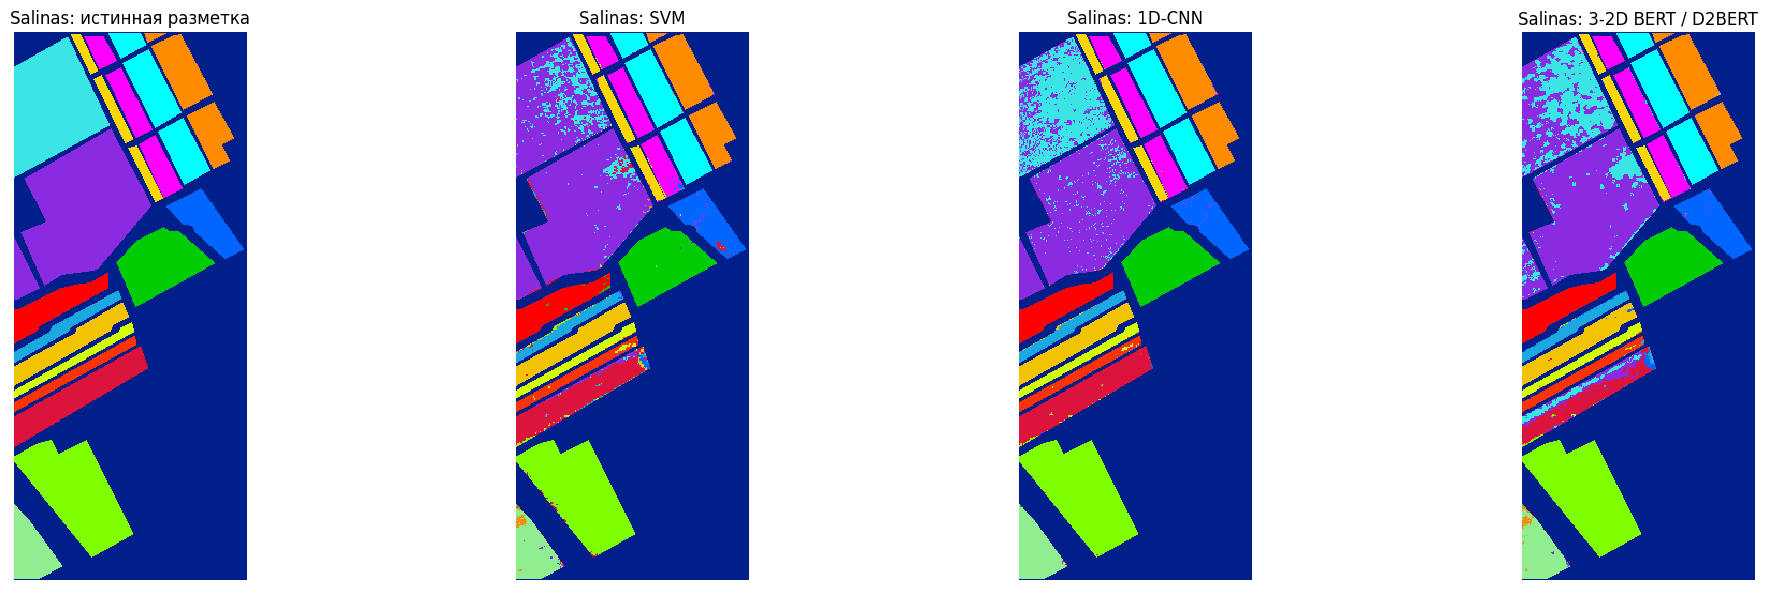

,model,test_size,test_OA,test_macro_F1,test_weighted_F1,dataset,best_epoch
0,SVM,0.7,0.862817,0.908073,0.843448,Salinas Valley,NaN
1,1D-CNN,0.9,0.947493,0.971709,0.946607,Salinas Valley,NaN
2,3-2D BERT / D2BERT,0.9,0.888150,0.931985,0.884257,Salinas Valley,11.0


,class_id,class_name,svm_f1,cnn_f1,D2BERT_f1
0,0,Brocoli_green_weeds_1,0.988489,0.999724,1.000000
1,1,Brocoli_green_weeds_2,0.992567,0.999553,0.999106
2,2,Fallow,0.944346,0.993810,0.961497
3,3,Fallow_rough_plow,0.980612,0.988442,0.987169
4,4,Fallow_smooth,0.970572,0.986584,0.987583
5,5,Stubble,0.998735,0.999017,0.996083
6,6,Celery,0.983445,0.997978,0.985441
7,7,Grapes_untrained,0.768325,0.890932,0.801155
8,8,Soil_vinyard_develop,0.987034,0.995894,0.995098
9,9,Corn_senesced_green_weeds,0.859048,0.978557,0.727544


In [40]:

# ------------------------------------------------------------
# Карта классификации 3-2D BERT на всей размеченной части Salinas
# ------------------------------------------------------------

salinas_all_labeled_idx = np.arange(len(y_all))

X_salinas_d2bert_all_t = build_d2bert_tensor(
    salinas_d2bert_final_preproc["cube_pca"],
    labeled_coords,
    salinas_all_labeled_idx,
    D2BERT_CONFIG
)

salinas_d2bert_all_pred = predict_torch_batches(
    salinas_d2bert_model_final,
    X_salinas_d2bert_all_t,
    batch_size=int(D2BERT_CONFIG["inference_batch_size"]),
    device=DEVICE
)

salinas_d2bert_pred_map = make_masked_map_from_indices(
    salinas_all_labeled_idx,
    salinas_d2bert_all_pred,
    gt.shape,
    labeled_coords
)

fig, axs = plt.subplots(1, 4, figsize=(22, 6))
plot_map(axs[0], salinas_gt_map, "Salinas: истинная разметка")
plot_map(axs[1], salinas_svm_pred_map, "Salinas: SVM")
plot_map(axs[2], salinas_cnn_pred_map, "Salinas: 1D-CNN")
plot_map(axs[3], salinas_d2bert_pred_map, "Salinas: 3-2D BERT / D2BERT")
plt.tight_layout()
plt.show()

salinas_summary_with_d2bert_df = pd.concat(
    [
        summary_df.assign(dataset="Salinas Valley"),
        salinas_d2bert_summary_df
    ],
    ignore_index=True
)

display(salinas_summary_with_d2bert_df)

salinas_per_class_compare_with_d2bert_df = per_class_compare_df.merge(
    salinas_d2bert_per_class_f1_df,
    on=["class_id", "class_name"],
    how="outer"
)

display(salinas_per_class_compare_with_d2bert_df)


## Обучение и тестирование 3-2D BERT на Pavia Centre

Для Pavia Centre используется та же логика, что и для Salinas: сначала определяется `best_epoch` по train/val-разбиению, затем модель переобучается на всей development-части и оценивается на holdout test. Для карты классификации предсказания переводятся обратно в исходные метки Pavia.


In [41]:

# ------------------------------------------------------------
# 3-2D BERT / D2BERT на Pavia Centre
# ------------------------------------------------------------

pavia_d2bert_indices = np.arange(len(y_pavia_all))

pavia_d2bert_dev_idx, pavia_d2bert_test_idx = train_test_split(
    pavia_d2bert_indices,
    test_size=CNN_TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_pavia_all
)

pavia_d2bert_train_idx, pavia_d2bert_val_idx = train_test_split(
    pavia_d2bert_dev_idx,
    test_size=CNN_VAL_SIZE_WITHIN_DEV,
    random_state=RANDOM_STATE,
    stratify=y_pavia_all[pavia_d2bert_dev_idx]
)

print("Pavia D2BERT train:", len(pavia_d2bert_train_idx))
print("Pavia D2BERT val  :", len(pavia_d2bert_val_idx))
print("Pavia D2BERT test :", len(pavia_d2bert_test_idx))

# 1) Подбор числа эпох по train/val
pavia_d2bert_preproc = build_d2bert_preprocessor(
    cube_arr=pavia_cube,
    labeled_coords_arr=pavia_labeled_coords,
    fit_indices=pavia_d2bert_train_idx,
    config=D2BERT_CONFIG
)

X_pavia_d2bert_train_t = build_d2bert_tensor(
    pavia_d2bert_preproc["cube_pca"],
    pavia_labeled_coords,
    pavia_d2bert_train_idx,
    D2BERT_CONFIG
)
X_pavia_d2bert_val_t = build_d2bert_tensor(
    pavia_d2bert_preproc["cube_pca"],
    pavia_labeled_coords,
    pavia_d2bert_val_idx,
    D2BERT_CONFIG
)

y_pavia_d2bert_train = y_pavia_all[pavia_d2bert_train_idx]
y_pavia_d2bert_val = y_pavia_all[pavia_d2bert_val_idx]

pavia_d2bert_model = D2BERT(
    seq_len=seq_len_d2bert,
    feature_dim=feature_dim_d2bert,
    d_model=int(D2BERT_CONFIG["d_model"]),
    num_classes=pavia_num_classes,
    num_layers=int(D2BERT_CONFIG["num_layers"]),
    num_heads=int(D2BERT_CONFIG["num_heads"])
).to(DEVICE)

pavia_d2bert_model, pavia_d2bert_history, pavia_d2bert_best_epoch = train_d2bert_with_early_stopping(
    model=pavia_d2bert_model,
    X_train_t=X_pavia_d2bert_train_t,
    y_train=y_pavia_d2bert_train,
    X_val_t=X_pavia_d2bert_val_t,
    y_val=y_pavia_d2bert_val,
    config=D2BERT_CONFIG,
    device=DEVICE
)

print("Pavia D2BERT best_epoch:", pavia_d2bert_best_epoch)

# 2) Финальная модель на всей development-части
if D2BERT_CONFIG["retrain_on_full_dev"]:
    pavia_d2bert_final_preproc = build_d2bert_preprocessor(
        cube_arr=pavia_cube,
        labeled_coords_arr=pavia_labeled_coords,
        fit_indices=pavia_d2bert_dev_idx,
        config=D2BERT_CONFIG
    )

    X_pavia_d2bert_dev_t = build_d2bert_tensor(
        pavia_d2bert_final_preproc["cube_pca"],
        pavia_labeled_coords,
        pavia_d2bert_dev_idx,
        D2BERT_CONFIG
    )

    pavia_d2bert_model_final, pavia_d2bert_final_history = fit_d2bert_for_fixed_epochs(
        X_train_t=X_pavia_d2bert_dev_t,
        y_train=y_pavia_all[pavia_d2bert_dev_idx],
        seq_len=seq_len_d2bert,
        feature_dim=feature_dim_d2bert,
        num_classes=pavia_num_classes,
        epochs=max(1, int(pavia_d2bert_best_epoch)),
        config=D2BERT_CONFIG,
        device=DEVICE
    )
else:
    pavia_d2bert_final_preproc = pavia_d2bert_preproc
    pavia_d2bert_model_final = pavia_d2bert_model
    pavia_d2bert_final_history = pavia_d2bert_history

# 3) Holdout test
X_pavia_d2bert_test_t = build_d2bert_tensor(
    pavia_d2bert_final_preproc["cube_pca"],
    pavia_labeled_coords,
    pavia_d2bert_test_idx,
    D2BERT_CONFIG
)

pavia_d2bert_test_pred = predict_torch_batches(
    pavia_d2bert_model_final,
    X_pavia_d2bert_test_t,
    batch_size=int(D2BERT_CONFIG["inference_batch_size"]),
    device=DEVICE
)

pavia_d2bert_test_metrics = compute_metrics_n_classes(
    y_pavia_all[pavia_d2bert_test_idx],
    pavia_d2bert_test_pred,
    pavia_num_classes
)

print("Pavia D2BERT test OA         :", round(pavia_d2bert_test_metrics["oa"], 6))
print("Pavia D2BERT test macro-F1   :", round(pavia_d2bert_test_metrics["macro_f1"], 6))
print("Pavia D2BERT test weighted-F1:", round(pavia_d2bert_test_metrics["weighted_f1"], 6))

print(classification_report(
    y_pavia_all[pavia_d2bert_test_idx],
    pavia_d2bert_test_pred,
    labels=np.arange(pavia_num_classes),
    target_names=PAVIA_CLASS_NAMES,
    digits=4,
    zero_division=0
))

pavia_d2bert_summary_df = pd.DataFrame([{
    "dataset": "Pavia Centre",
    "model": "3-2D BERT / D2BERT",
    "test_size": CNN_TEST_SIZE,
    "best_epoch": pavia_d2bert_best_epoch,
    "test_OA": pavia_d2bert_test_metrics["oa"],
    "test_macro_F1": pavia_d2bert_test_metrics["macro_f1"],
    "test_weighted_F1": pavia_d2bert_test_metrics["weighted_f1"]
}])

pavia_d2bert_per_class_f1_df = build_d2bert_per_class_df(
    pavia_d2bert_test_metrics["per_class_f1"],
    PAVIA_CLASS_NAMES,
    model_name="D2BERT"
)

display(pavia_d2bert_summary_df)
display(pavia_d2bert_per_class_f1_df)


Pavia D2BERT train: 11852
Pavia D2BERT val  : 2963
Pavia D2BERT test : 133337


Training D2BERT:  40%|████      | 12/30 [00:13<00:20,  1.15s/it]

Early stopping at epoch 13
Pavia D2BERT best_epoch: 3



Retraining D2BERT: 100%|██████████| 3/3 [00:03<00:00,  1.16s/it]


Pavia D2BERT test OA         : 0.932434
Pavia D2BERT test macro-F1   : 0.767075
Pavia D2BERT test weighted-F1: 0.927472
               precision    recall  f1-score   support

Pavia_class_1     0.9997    0.9907    0.9952     59374
Pavia_class_2     0.9475    0.9392    0.9433      6838
Pavia_class_3     0.8222    0.8562    0.8388      2781
Pavia_class_4     0.0945    0.0050    0.0094      2417
Pavia_class_5     0.5827    0.9755    0.7296      5926
Pavia_class_6     0.9803    0.5911    0.7375      8323
Pavia_class_7     0.6017    0.8158    0.6926      6558
Pavia_class_8     0.9984    0.9882    0.9933     38543
Pavia_class_9     0.9389    0.9903    0.9639      2577

     accuracy                         0.9324    133337
    macro avg     0.7740    0.7947    0.7671    133337
 weighted avg     0.9361    0.9324    0.9275    133337



,dataset,model,test_size,best_epoch,test_OA,test_macro_F1,test_weighted_F1
0,Pavia Centre,3-2D BERT / D2BERT,0.9,3,0.932434,0.767075,0.927472


,class_id,class_name,D2BERT_f1
0,0,Pavia_class_1,0.995195
1,1,Pavia_class_2,0.943302
2,2,Pavia_class_3,0.838823
3,3,Pavia_class_4,0.009434
4,4,Pavia_class_5,0.729602
5,5,Pavia_class_6,0.737521
6,6,Pavia_class_7,0.692601
7,7,Pavia_class_8,0.993272
8,8,Pavia_class_9,0.963928


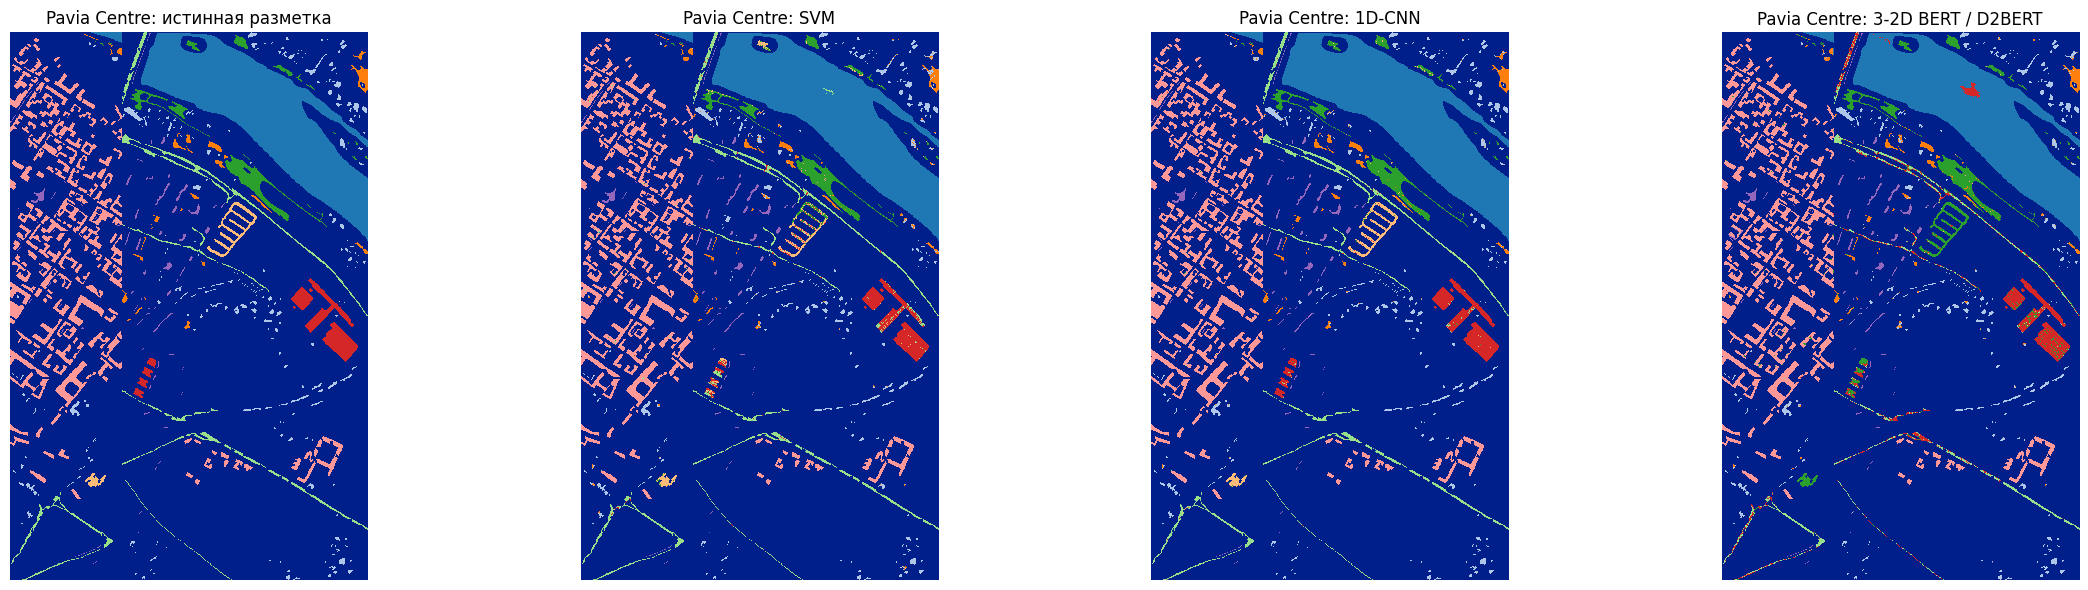

,dataset,model,test_size,test_OA,test_macro_F1,test_weighted_F1,best_epoch
0,Pavia Centre,SVM,0.7,0.969028,0.896738,0.968675,NaN
1,Pavia Centre,1D-CNN (Hu),0.9,0.991698,0.973497,0.991717,NaN
2,Pavia Centre,3-2D BERT / D2BERT,0.9,0.932434,0.767075,0.927472,3.0


In [42]:

# ------------------------------------------------------------
# Карта классификации 3-2D BERT на всей размеченной части Pavia Centre
# ------------------------------------------------------------

pavia_all_labeled_idx = np.arange(len(y_pavia_all))

X_pavia_d2bert_all_t = build_d2bert_tensor(
    pavia_d2bert_final_preproc["cube_pca"],
    pavia_labeled_coords,
    pavia_all_labeled_idx,
    D2BERT_CONFIG
)

pavia_d2bert_all_pred = predict_torch_batches(
    pavia_d2bert_model_final,
    X_pavia_d2bert_all_t,
    batch_size=int(D2BERT_CONFIG["inference_batch_size"]),
    device=DEVICE
)

pavia_d2bert_pred_map = np.zeros_like(pavia_gt, dtype=np.int64)
pavia_d2bert_pred_map[pavia_labeled_coords[:, 0], pavia_labeled_coords[:, 1]] = np.array(
    [pavia_index_to_label[idx] for idx in pavia_d2bert_all_pred],
    dtype=np.int64
)

fig, axs = plt.subplots(1, 4, figsize=(24, 6))

axs[0].imshow(pavia_gt_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[0].set_title("Pavia Centre: истинная разметка")
axs[0].axis("off")

axs[1].imshow(pavia_svm_pred_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[1].set_title("Pavia Centre: SVM")
axs[1].axis("off")

axs[2].imshow(pavia_cnn_pred_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[2].set_title("Pavia Centre: 1D-CNN")
axs[2].axis("off")

axs[3].imshow(pavia_d2bert_pred_map, cmap=pavia_cmap, vmin=0, vmax=int(pavia_gt.max()), interpolation="nearest")
axs[3].set_title("Pavia Centre: 3-2D BERT / D2BERT")
axs[3].axis("off")

plt.tight_layout()
plt.show()

pavia_summary_with_d2bert_df = pd.concat(
    [
        pavia_summary_df,
        pavia_d2bert_summary_df
    ],
    ignore_index=True
)

display(pavia_summary_with_d2bert_df)


In [43]:

# ------------------------------------------------------------
# Сохранение метрик и весов 3-2D BERT
# ------------------------------------------------------------

torch.save(
    salinas_d2bert_model_final.state_dict(),
    ARTIFACT_DIR / "salinas_d2bert_state_dict.pt"
)

torch.save(
    pavia_d2bert_model_final.state_dict(),
    ARTIFACT_DIR / "pavia_d2bert_state_dict.pt"
)

salinas_d2bert_summary_df.to_csv(
    ARTIFACT_DIR / "salinas_d2bert_summary_test_metrics.csv",
    index=False
)
salinas_d2bert_per_class_f1_df.to_csv(
    ARTIFACT_DIR / "salinas_d2bert_per_class_f1.csv",
    index=False
)

pavia_d2bert_summary_df.to_csv(
    ARTIFACT_DIR / "pavia_d2bert_summary_test_metrics.csv",
    index=False
)
pavia_d2bert_per_class_f1_df.to_csv(
    ARTIFACT_DIR / "pavia_d2bert_per_class_f1.csv",
    index=False
)

combined_summary_with_d2bert_df = pd.concat(
    [
        salinas_summary_with_d2bert_df,
        pavia_summary_with_d2bert_df
    ],
    ignore_index=True
)

combined_summary_with_d2bert_df.to_csv(
    ARTIFACT_DIR / "combined_summary_with_d2bert.csv",
    index=False
)

display(combined_summary_with_d2bert_df)

print("D2BERT artifacts saved to:", ARTIFACT_DIR.resolve())


,model,test_size,test_OA,test_macro_F1,test_weighted_F1,dataset,best_epoch
0,SVM,0.7,0.862817,0.908073,0.843448,Salinas Valley,NaN
1,1D-CNN,0.9,0.947493,0.971709,0.946607,Salinas Valley,NaN
2,3-2D BERT / D2BERT,0.9,0.888150,0.931985,0.884257,Salinas Valley,11.0
3,SVM,0.7,0.969028,0.896738,0.968675,Pavia Centre,NaN
4,1D-CNN (Hu),0.9,0.991698,0.973497,0.991717,Pavia Centre,NaN
5,3-2D BERT / D2BERT,0.9,0.932434,0.767075,0.927472,Pavia Centre,3.0


D2BERT artifacts saved to: C:\Users\denis\Desktop\111\artifacts_salinas_literature_1dcnn
